Projeto M2 — Segmentação e Morfologia

Universidade do Vale do Itajaí

Curso: Ciência da Computação
Disciplina: Processamento de Imagens
Professor: Felipe Viel
Acadêmicos: Aquilis Visintainer, Filipe Dietrich e Nilton Alves

#Projeto 1 — Segmentação baseada em clusters K-means
Objetivo
Implementar e comparar duas configurações de segmentação de imagens utilizando o algoritmo K-means:
- RGB (3D): agrupamento considerando as três componentes de cor dos pixels.
- RGB+XY (5D): agrupamento considerando as três componentes de cor e a posição espacial de cada pixel.
Os resultados serão comparados para avaliar a influência da informação espacial na separação dos objetos. Também será apresentado um gráfico de dispersão tridimensional da imagem 2or4objects.jpg, utilizando os canais RGB.

Preparação do ambiente e caracterização inicial
Antes de aplicar os métodos de segmentação, realizamos o carregamento das imagens fornecidas para o projeto e verificamos suas dimensões e características visuais.

Nesta etapa, as imagens serão mantidas em sua resolução original, permitindo observar a quantidade de objetos, as diferenças de cores e as características do fundo. Essas informações serão utilizadas posteriormente para definir os parâmetros da segmentação, principalmente o número de agrupamentos (K).

As imagens serão carregadas utilizando OpenCV e exibidas com Matplotlib. Como o OpenCV utiliza o padrão BGR, será realizada a conversão para RGB apenas durante a visualização, garantindo a representação correta das cores.


Imagem: 2apples.jpg
Dimensões: 538 x 358 pixels
Canais de cor: 3
Total de pixels: 192604

Imagem: 2or4objects.jpg
Dimensões: 700 x 531 pixels
Canais de cor: 3
Total de pixels: 371700


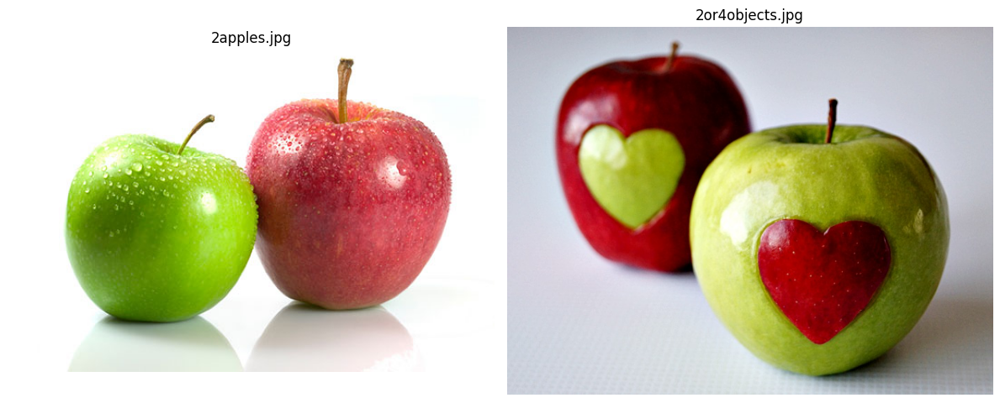

In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt


# FUNÇÃO PARA CARREGAR AS IMAGENS
# Realiza a leitura dos arquivos disponíveis na pasta do Colab
# e armazena cada imagem em um dicionário.

def carregar_imagens(nomes_arquivos):
    imagens = {}

    for nome in nomes_arquivos:

        # Carrega a imagem mantendo os três canais de cor (BGR).
        img = cv2.imread(f"/content/{nome}", cv2.IMREAD_COLOR)

        # Verifica se o arquivo foi carregado corretamente.
        if img is None:
            print(f"Não foi possível carregar: {nome}")
            continue

        # Armazena a imagem mantendo sua resolução original.
        imagens[nome] = img

        altura, largura, canais = img.shape

        print(f"\nImagem: {nome}")
        print(f"Dimensões: {largura} x {altura} pixels")
        print(f"Canais de cor: {canais}")
        print(f"Total de pixels: {largura * altura}")

    return imagens


# FUNÇÃO PARA EXIBIR AS IMAGENS ORIGINAIS
# Organiza as imagens lado a lado para observar suas características
# antes da aplicação dos métodos de segmentação.

def exibir_imagens_originais(imagens):

    if not imagens:
        print("Nenhuma imagem foi carregada.")
        return

    quantidade = len(imagens)

    fig, axes = plt.subplots(
        1, quantidade,
        figsize=(6 * quantidade, 5),
        squeeze=False
    )

    for indice, (nome, img) in enumerate(imagens.items()):

        # Converte BGR para RGB para exibir as cores corretamente.
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[0, indice].imshow(img_rgb)
        axes[0, indice].set_title(nome, fontsize=12)
        axes[0, indice].axis("off")

    plt.tight_layout()
    plt.show()


# DEFINIÇÃO DAS IMAGENS DO PROJETO 1
# Utiliza as imagens de maçãs e objetos fornecidas pelo professor.

nomes_arquivos = [
    "2apples.jpg",
    "2or4objects.jpg",
]

# Carrega as imagens para as próximas etapas.
imagens_originais = carregar_imagens(nomes_arquivos)

# Exibe as imagens originais para inspeção visual.
exibir_imagens_originais(imagens_originais)



## 2. Segmentação utilizando K-means RGB (3D)

### Justificativa da escolha do método

O algoritmo K-means foi utilizado para segmentar as imagens a partir da similaridade entre as cores dos pixels, conforme solicitado no enunciado.

Nesta primeira configuração, cada pixel é representado por três características correspondentes aos canais vermelho (R), verde (G) e azul (B). O algoritmo organiza esses pixels em K agrupamentos, utilizando a distância euclidiana para determinar a proximidade entre as cores.

Inicialmente, os centroides são selecionados aleatoriamente entre os pixels da imagem. Em seguida, cada pixel é associado ao centroide mais próximo, e os centroides são recalculados a partir da média das cores dos pixels pertencentes a cada grupo. Esse processo é repetido até atingir o critério de convergência ou o número máximo de iterações.

Para os experimentos, foram definidos os seguintes valores:

- **2apples.jpg — K = 3:** considerando as duas regiões principais de cores das maçãs (verde e vermelha) e o fundo claro.
- **2or4objects.jpg — K = 5:** considerando as duas maçãs, as duas regiões adicionais em formato de coração e o fundo.

Esses valores representam configurações iniciais de agrupamento. Como o K-means classifica os pixels por similaridade de cor, os clusters não correspondem necessariamente a objetos completos ou individualizados.

A utilização apenas do espaço RGB permite avaliar a capacidade do algoritmo de separar regiões com diferentes tonalidades, mas apresenta uma limitação importante: pixels de cores semelhantes podem ser agrupados mesmo quando estão localizados em posições distantes da imagem.

Espera-se obter regiões com cores mais uniformes, permitindo identificar os principais agrupamentos cromáticos. Posteriormente, esses resultados serão comparados com a configuração RGB+XY para avaliar a influência da posição espacial na segmentação.



Processando 2apples.jpg com K = 3...
Iterações executadas: 68
Convergência atingida: True
Centroides RGB encontrados:
Grupo 1: R=120.2, G=165.0, B=24.7
Grupo 2: R=247.9, G=247.8, B=243.5
Grupo 3: R=177.1, G=79.1, B=77.2


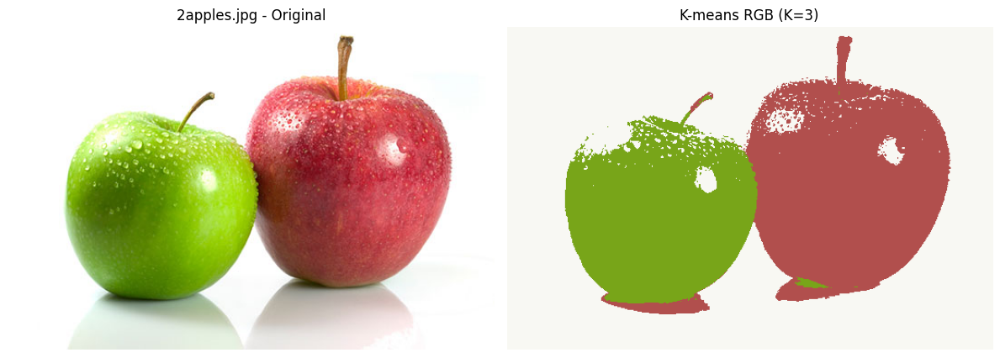


Processando 2or4objects.jpg com K = 5...
Iterações executadas: 31
Convergência atingida: True
Centroides RGB encontrados:
Grupo 1: R=132.6, G=133.8, B=46.5
Grupo 2: R=205.5, G=208.7, B=214.5
Grupo 3: R=155.9, G=10.3, B=16.6
Grupo 4: R=66.5, G=32.8, B=4.7
Grupo 5: R=188.5, G=189.2, B=128.6


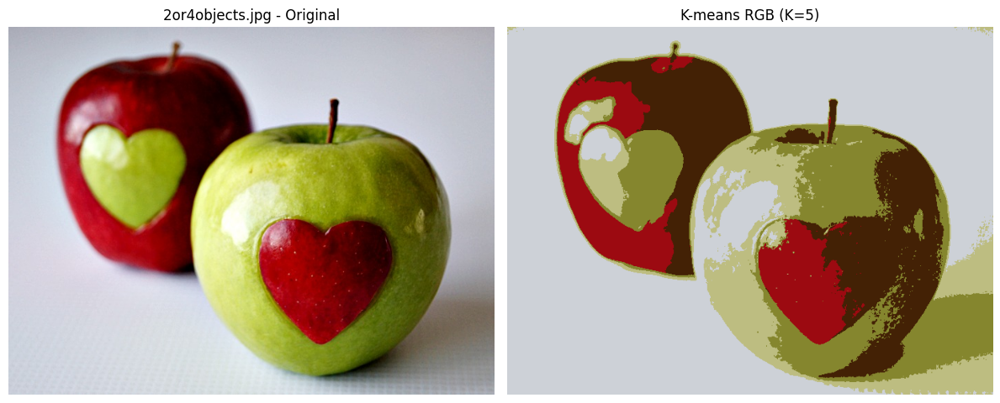

In [ ]:

# FUNÇÃO PARA EXECUTAR O ALGORITMO K-MEANS
# Agrupa os pixels de acordo com a distância entre suas
# características e os centroides de cada agrupamento.

def executar_kmeans(dados, k, max_iter=100, tolerancia=0.1, semente=42):

    # Define uma semente para reproduzir a inicialização
    # dos centroides nas diferentes execuções.
    gerador = np.random.default_rng(semente)

    quantidade_pixels = dados.shape[0]

    # Verifica se a quantidade de clusters é válida.
    if k < 1 or k > quantidade_pixels:
        raise ValueError("Valor de K inválido.")

    # Seleciona K pixels aleatórios como centroides iniciais.
    indices = gerador.choice(
        quantidade_pixels,
        size=k,
        replace=False
    )

    centroides = dados[indices].copy()
    convergiu = False

    # Executa as etapas de atribuição e atualização
    # até atingir a convergência ou o limite de iterações.
    for iteracao in range(max_iter):

        # ETAPA 1: ATRIBUIÇÃO DOS PIXELS
        # Calcula a distância euclidiana ao quadrado entre
        # cada pixel e todos os centroides.
        # A raiz quadrada é dispensada porque não altera
        # a identificação do centroide mais próximo.
        distancias = np.sum(
            (dados[:, None, :] - centroides[None, :, :]) ** 2,
            axis=2
        )

        # Identifica o centroide mais próximo de cada pixel
        # e registra o índice do agrupamento correspondente.
        rotulos = np.argmin(distancias, axis=1)

        # ETAPA 2: ATUALIZAÇÃO DOS CENTROIDES
        novos_centroides = centroides.copy()

        for grupo in range(k):

            # Seleciona os pixels classificados no grupo atual.
            pixels_grupo = dados[rotulos == grupo]

            if len(pixels_grupo) > 0:

                # Recalcula o centroide utilizando a média
                # das características dos pixels do grupo.
                novos_centroides[grupo] = pixels_grupo.mean(axis=0)

            else:

                # Reinicializa um agrupamento vazio para evitar
                # divisões por zero e manter K centroides.
                novos_centroides[grupo] = dados[
                    gerador.integers(quantidade_pixels)
                ]

        # ETAPA 3: VERIFICAÇÃO DA CONVERGÊNCIA
        # Calcula o deslocamento total dos centroides
        # entre a iteração anterior e a atual.
        deslocamento = np.linalg.norm(
            novos_centroides - centroides
        )

        centroides = novos_centroides

        # Interrompe as iterações quando o deslocamento
        # fica abaixo da tolerância estabelecida.
        if deslocamento < tolerancia:
            convergiu = True
            break

    # Atualiza os rótulos de acordo com os centroides finais.
    # Isso mantém a classificação compatível com a última
    # atualização realizada pelo algoritmo.
    distancias_finais = np.sum(
        (dados[:, None, :] - centroides[None, :, :]) ** 2,
        axis=2
    )

    rotulos = np.argmin(distancias_finais, axis=1)

    return rotulos, centroides, iteracao + 1, convergiu


# FUNÇÃO PARA SEGMENTAÇÃO NO ESPAÇO RGB (3D)
# Converte a imagem em uma matriz de pixels RGB, executa
# o K-means e reconstrói a imagem com as cores dos centroides.

def segmentar_kmeans_rgb(img_bgr, k):

    # Converte a imagem do padrão BGR para RGB.
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    altura, largura = img_rgb.shape[:2]

    # Transforma a imagem em uma matriz de N pixels x 3 canais.
    # Cada linha representa um pixel com valores R, G e B.
    dados = img_rgb.reshape(-1, 3).astype(np.float32)

    # Executa o agrupamento utilizando somente os canais RGB.
    rotulos, centroides, iteracoes, convergiu = executar_kmeans(
        dados,
        k=k,
        max_iter=100,
        tolerancia=0.1,
        semente=42
    )

    # Substitui cada pixel pela cor média do seu agrupamento.
    # Os valores são arredondados e limitados ao intervalo 0-255.
    pixels_segmentados = np.clip(
        np.rint(centroides[rotulos]),
        0,
        255
    ).astype(np.uint8)

    # Reconstrói a imagem segmentada em suas dimensões originais.
    img_segmentada = pixels_segmentados.reshape(
        altura, largura, 3
    )

    # Reorganiza os rótulos em uma matriz da mesma dimensão
    # espacial da imagem original.
    mapa_rotulos = rotulos.reshape(altura, largura)

    # Armazena os resultados para reutilização nas próximas etapas.
    return {
        "original": img_rgb,
        "segmentada": img_segmentada,
        "rotulos": mapa_rotulos,
        "centroides": centroides,
        "iteracoes": iteracoes,
        "convergiu": convergiu,
        "k": k
    }


# FUNÇÃO PARA EXIBIR OS RESULTADOS
# Apresenta a imagem original e a imagem segmentada lado a lado,
# permitindo observar as regiões formadas pelo agrupamento RGB.

def exibir_resultado_kmeans_rgb(nome, resultado):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(resultado["original"])
    axes[0].set_title(f"{nome} - Original")
    axes[0].axis("off")

    axes[1].imshow(resultado["segmentada"])
    axes[1].set_title(
        f"K-means RGB (K={resultado['k']})"
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO K-MEANS RGB
# Define a quantidade inicial de clusters para cada imagem.

valores_k = {
    "2apples.jpg": 3,
    "2or4objects.jpg": 5
}

# Armazena separadamente os resultados de cada imagem.
resultados_kmeans_rgb = {}

for nome, k in valores_k.items():

    print(f"\nProcessando {nome} com K = {k}...")

    resultado = segmentar_kmeans_rgb(
        imagens_originais[nome],
        k
    )

    resultados_kmeans_rgb[nome] = resultado

    print(f"Iterações executadas: {resultado['iteracoes']}")
    print(f"Convergência atingida: {resultado['convergiu']}")

    print("Centroides RGB encontrados:")

    for indice, centroide in enumerate(resultado["centroides"]):
        print(
            f"Grupo {indice + 1}: "
            f"R={centroide[0]:.1f}, "
            f"G={centroide[1]:.1f}, "
            f"B={centroide[2]:.1f}"
        )

    exibir_resultado_kmeans_rgb(nome, resultado)



### Análise dos resultados — K-means RGB (3D)

A aplicação do K-means no espaço RGB demonstrou a capacidade do algoritmo de agrupar pixels com características cromáticas semelhantes, reduzindo a variedade de cores das imagens e evidenciando suas principais regiões.

**2apples.jpg — K = 3**

O algoritmo apresentou uma separação visual satisfatória entre as maçãs verde e vermelha e o fundo claro, convergindo após 68 iterações.

Entretanto, observamos algumas classificações inadequadas nas regiões de brilho, reflexos e sombras. Parte dos reflexos presentes nas maçãs foi agrupada com o fundo, enquanto algumas regiões próximas aos contornos receberam cores pertencentes a outros agrupamentos.

Essas alterações demonstram que a classificação depende exclusivamente dos valores RGB, sem considerar a localização dos pixels ou os limites reais dos objetos.

**2or4objects.jpg — K = 5**

A segunda imagem apresentou uma segmentação mais fragmentada, com cinco agrupamentos e convergência após 31 iterações.

Os clusters conseguiram representar diferentes tonalidades presentes nas maçãs, nos corações e no fundo. Entretanto, as variações de iluminação e sombreamento fizeram com que diferentes regiões de um mesmo objeto fossem classificadas em agrupamentos distintos.

Também observamos que regiões com cores semelhantes foram agrupadas independentemente de sua localização, dificultando a separação individual dos objetos e dos detalhes presentes nas maçãs.

**Considerações preliminares**

Os resultados demonstram que o K-means RGB é eficiente para identificar grupos de cores, mas não garante a separação individual dos objetos presentes na imagem.

A ausência de informações espaciais representa uma limitação importante, especialmente em imagens com sombras, reflexos e regiões de cores semelhantes.

Essas observações serão utilizadas posteriormente na comparação com o K-means RGB+XY, para verificar como a inclusão das coordenadas espaciais influencia os agrupamentos.



## 3. Visualização dos agrupamentos no espaço RGB (3D)

### Justificativa da visualização

Para analisar a distribuição dos agrupamentos produzidos pelo K-means RGB, foi desenvolvido um gráfico de dispersão tridimensional utilizando a imagem `2or4objects.jpg`.

Cada ponto do gráfico representa um pixel da imagem original, posicionado de acordo com seus valores de vermelho (R), verde (G) e azul (B). Os pontos recebem a cor do centroide do agrupamento ao qual pertencem, permitindo visualizar como o algoritmo classificou as diferentes tonalidades.

Os centroides também serão representados no gráfico, destacando as posições médias dos cinco agrupamentos identificados pelo algoritmo.

Para reduzir o tempo de renderização e evitar a sobreposição excessiva de pontos, será utilizada uma amostra aleatória de até 10.000 pixels. A amostragem não altera os resultados do K-means, pois utiliza os agrupamentos e centroides já calculados na etapa anterior.

Espera-se observar a formação de grupos de pixels com características cromáticas semelhantes, identificando a distribuição das tonalidades e possíveis sobreposições entre regiões.

Essa representação também permitirá compreender uma limitação do K-means RGB: pixels pertencentes a diferentes objetos podem ocupar regiões próximas no espaço de cores e, consequentemente, receber a mesma classificação.


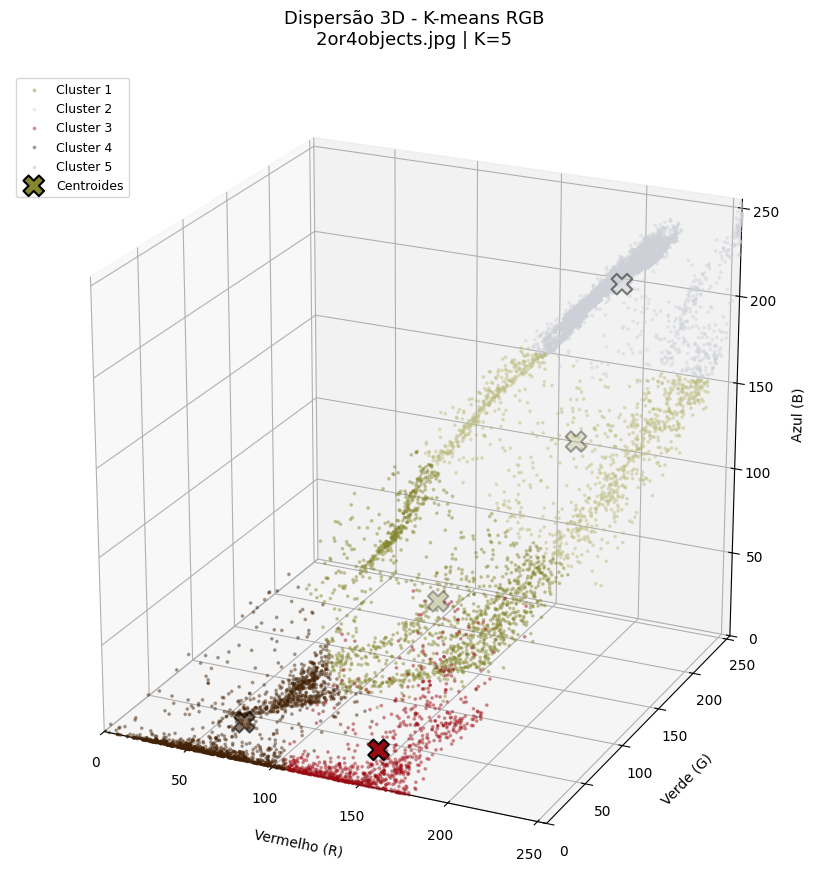

Total de pixels da imagem: 371700
Pixels utilizados no gráfico: 10000
Quantidade de clusters: 5


In [ ]:

# FUNÇÃO PARA GERAR O GRÁFICO DE DISPERSÃO 3D
# Representa os pixels no espaço RGB e identifica os
# agrupamentos formados pelo K-means e seus centroides.

def plotar_kmeans_rgb_3d(resultado, nome_imagem, amostra=10000):

    # Recupera a imagem original em RGB, os rótulos
    # de classificação e os centroides calculados.
    img_rgb = resultado["original"]
    rotulos = resultado["rotulos"].reshape(-1)
    centroides = resultado["centroides"]

    # Converte a imagem em uma matriz de N pixels x 3 canais.
    # Cada linha armazena os valores R, G e B de um pixel.
    pixels = img_rgb.reshape(-1, 3)

    quantidade_pixels = len(pixels)

    # Define uma semente para manter a mesma amostra
    # em diferentes execuções do gráfico.
    gerador = np.random.default_rng(42)

    # Seleciona uma amostra aleatória dos pixels para
    # reduzir o tempo necessário para gerar o gráfico.
    quantidade_amostra = min(amostra, quantidade_pixels)

    indices = gerador.choice(
        quantidade_pixels,
        size=quantidade_amostra,
        replace=False
    )

    # Mantém os valores RGB originais e seus respectivos
    # rótulos de agrupamento.
    pixels_amostra = pixels[indices]
    rotulos_amostra = rotulos[indices]

    # Cria a figura e configura os três eixos do espaço RGB.
    fig = plt.figure(figsize=(11, 9))
    ax = fig.add_subplot(111, projection="3d")

    # Percorre os agrupamentos formados pelo K-means.
    for grupo in range(len(centroides)):

        # Identifica os pixels pertencentes ao grupo atual.
        mascara = rotulos_amostra == grupo
        pixels_grupo = pixels_amostra[mascara]

        # Normaliza a cor do centroide para o intervalo 0-1,
        # utilizado pelo Matplotlib na representação das cores.
        cor_grupo = np.clip(
            centroides[grupo] / 255.0,
            0,
            1
        )

        # Posiciona cada pixel utilizando suas coordenadas RGB.
        # A cor exibida representa o agrupamento atribuído.
        ax.scatter(
            pixels_grupo[:, 0],
            pixels_grupo[:, 1],
            pixels_grupo[:, 2],
            color=cor_grupo,
            s=3,
            alpha=0.35,
            label=f"Cluster {grupo + 1}"
        )

    # Destaca os centroides com marcadores maiores,
    # utilizando a cor média de cada agrupamento.
    ax.scatter(
        centroides[:, 0],
        centroides[:, 1],
        centroides[:, 2],
        c=np.clip(centroides / 255.0, 0, 1),
        marker="X",
        s=220,
        edgecolors="black",
        linewidths=1.5,
        label="Centroides"
    )

    # Identifica os eixos e define seus limites,
    # considerando imagens RGB de 8 bits.
    ax.set_xlabel("Vermelho (R)", labelpad=10)
    ax.set_ylabel("Verde (G)", labelpad=10)
    ax.set_zlabel("Azul (B)", labelpad=10)

    ax.set_xlim(0, 255)
    ax.set_ylim(0, 255)
    ax.set_zlim(0, 255)

    # Mantém a mesma proporção visual entre os três eixos.
    ax.set_box_aspect((1, 1, 1))

    # Define o ângulo inicial de visualização.
    ax.view_init(elev=22, azim=-65)

    ax.set_title(
        f"Dispersão 3D - K-means RGB\n"
        f"{nome_imagem} | K={resultado['k']}",
        fontsize=13,
        pad=20
    )

    ax.legend(loc="upper left", fontsize=9)

    plt.tight_layout()
    plt.show()

    print(f"Total de pixels da imagem: {quantidade_pixels}")
    print(f"Pixels utilizados no gráfico: {quantidade_amostra}")
    print(f"Quantidade de clusters: {len(centroides)}")


# APLICAÇÃO DO GRÁFICO 3D
# Utiliza os agrupamentos obtidos anteriormente para
# a imagem exigida no enunciado.

resultado_3d = resultados_kmeans_rgb["2or4objects.jpg"]

plotar_kmeans_rgb_3d(
    resultado_3d,
    nome_imagem="2or4objects.jpg",
    amostra=10000
)



### Análise dos resultados — Dispersão 3D

O gráfico de dispersão tridimensional permitiu visualizar a distribuição dos pixels da imagem `2or4objects.jpg` no espaço RGB e os cinco agrupamentos formados pelo algoritmo K-means.

Observamos que os pixels foram distribuídos de acordo com suas características cromáticas, formando regiões associadas principalmente às tonalidades de vermelho, verde, amarelo-esverdeado, marrom-escuro e cinza-claro.

Os centroides, representados pelos marcadores em formato de X, indicam as cores médias utilizadas como referência para cada agrupamento. A distribuição dos pontos demonstra que algumas tonalidades apresentam maior concentração em determinadas regiões do espaço RGB, enquanto outras formam distribuições alongadas e próximas dos limites entre os clusters.

O agrupamento correspondente às tonalidades claras apresentou uma concentração de pixels com valores elevados nos três canais, associada principalmente ao fundo da imagem. Já os agrupamentos de tonalidades vermelhas e escuras ocuparam regiões com menor intensidade nos canais verde e azul.

Para facilitar a visualização, foram selecionados aleatoriamente 10.000 pixels dos 371.700 presentes na imagem. Essa amostragem foi utilizada exclusivamente na construção do gráfico, mantendo os resultados da segmentação original.

De maneira geral, o gráfico confirma que o K-means RGB realiza o agrupamento com base na proximidade entre as cores, independentemente da localização dos pixels na imagem.

Essa característica explica por que diferentes objetos podem compartilhar um mesmo agrupamento quando apresentam tonalidades semelhantes, reforçando a limitação da segmentação baseada exclusivamente em informações cromáticas.



## 4. Segmentação utilizando K-means RGB+XY (5D)

### 4.1 Hipótese inicial

Na configuração anterior, o K-means utilizou exclusivamente os canais RGB para realizar o agrupamento dos pixels. Embora tenha identificado as principais regiões cromáticas, observamos que pixels pertencentes a objetos diferentes poderiam receber a mesma classificação quando apresentavam cores semelhantes.

Para avaliar a influência da localização dos pixels, implementamos a segunda configuração solicitada no enunciado, utilizando cinco características: R, G, B, X e Y.

Nossa hipótese inicial é que a inclusão das coordenadas espaciais poderá favorecer a formação de agrupamentos mais localizados, reduzindo a associação entre regiões distantes que apresentam cores semelhantes.

As coordenadas X e Y serão normalizadas para o intervalo de 0 a 255, aproximando sua escala numérica da utilizada pelos canais RGB.

Inicialmente, utilizaremos um peso espacial de 0,5, buscando equilibrar a influência das coordenadas e das componentes de cor na distância euclidiana.

Para manter as condições de comparação com o K-means RGB (3D), serão utilizados os mesmos valores de K:

- **2apples.jpg:** K = 3
- **2or4objects.jpg:** K = 5

Também serão mantidos a semente aleatória 42, o limite de 100 iterações e a tolerância de convergência de 0,1.

Espera-se que os agrupamentos apresentem maior continuidade espacial, mantendo a distinção entre as principais regiões cromáticas das imagens.


In [ ]:

# FUNÇÃO PARA CONSTRUIR O ESPAÇO RGB+XY (5D)
# Combina os canais de cor com as coordenadas espaciais,
# representando cada pixel por cinco características.

def preparar_dados_rgbxy(img_bgr, peso_espacial=0.5):

    # Converte a imagem do padrão BGR para RGB.
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    altura, largura = img_rgb.shape[:2]

    # Organiza os valores RGB em uma matriz de N pixels x 3 canais.
    dados_rgb = img_rgb.reshape(-1, 3).astype(np.float32)

    # Gera as coordenadas X e Y de cada pixel da imagem.
    # X representa a coluna e Y representa a linha.
    coordenadas_y, coordenadas_x = np.indices(
        (altura, largura),
        dtype=np.float32
    )

    # Normaliza as coordenadas para o intervalo de 0 a 255,
    # aproximando sua escala da utilizada pelos canais RGB.
    x_normalizado = coordenadas_x / max(largura - 1, 1) * 255.0
    y_normalizado = coordenadas_y / max(altura - 1, 1) * 255.0

    # Aplica o peso espacial para controlar a influência
    # das coordenadas no cálculo das distâncias.
    x_ponderado = x_normalizado * peso_espacial
    y_ponderado = y_normalizado * peso_espacial

    # Combina os cinco atributos em uma única matriz.
    # Cada linha contém R, G, B, X e Y de um pixel.
    dados_rgbxy = np.column_stack((
        dados_rgb,
        x_ponderado.reshape(-1),
        y_ponderado.reshape(-1)
    ))

    return dados_rgbxy, img_rgb


# FUNÇÃO PARA SEGMENTAÇÃO K-MEANS RGB+XY (5D)
# Executa o agrupamento considerando simultaneamente
# as características cromáticas e espaciais dos pixels.

def segmentar_kmeans_rgbxy(img_bgr, k, peso_espacial=0.5):

    # Constrói a matriz com as cinco características.
    dados, img_rgb = preparar_dados_rgbxy(
        img_bgr,
        peso_espacial
    )

    altura, largura = img_rgb.shape[:2]

    # Reutiliza o K-means implementado anteriormente.
    # O algoritmo considera todas as cinco características
    # para calcular as distâncias e atualizar os centroides.
    rotulos, centroides, iteracoes, convergiu = executar_kmeans(
        dados,
        k=k,
        max_iter=100,
        tolerancia=0.1,
        semente=42
    )

    # Recupera somente as componentes RGB dos centroides.
    # As coordenadas espaciais participam do agrupamento,
    # mas não são utilizadas como cores na imagem final.
    cores_centroides = centroides[:, :3]

    # Arredonda e limita os valores RGB ao intervalo 0-255.
    cores_centroides = np.clip(
        np.rint(cores_centroides),
        0,
        255
    ).astype(np.uint8)

    # Substitui cada pixel pela cor média do seu agrupamento.
    pixels_segmentados = cores_centroides[rotulos]

    # Reconstrói a imagem segmentada nas dimensões originais.
    img_segmentada = pixels_segmentados.reshape(
        altura, largura, 3
    )

    # Reorganiza os rótulos para preservar a localização
    # dos agrupamentos na imagem.
    mapa_rotulos = rotulos.reshape(altura, largura)

    # Armazena os resultados para reutilização nas
    # comparações e nas operações morfológicas.
    return {
        "original": img_rgb,
        "segmentada": img_segmentada,
        "rotulos": mapa_rotulos,
        "centroides": centroides,
        "iteracoes": iteracoes,
        "convergiu": convergiu,
        "k": k,
        "peso_espacial": peso_espacial
    }


# FUNÇÃO PARA EXIBIR A SEGMENTAÇÃO RGB+XY
# Apresenta a imagem original e a imagem segmentada,
# permitindo comparar visualmente os agrupamentos.

def exibir_resultado_kmeans_rgbxy(nome, resultado):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Exibe a imagem original como referência.
    axes[0].imshow(resultado["original"])
    axes[0].set_title(f"{nome} - Original")
    axes[0].axis("off")

    # Exibe os agrupamentos produzidos pelo K-means RGB+XY.
    axes[1].imshow(resultado["segmentada"])
    axes[1].set_title(
        f"K-means RGB+XY (K={resultado['k']})"
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()



Processando 2apples.jpg com K = 3...
Peso espacial: 0.5
Iterações executadas: 19
Convergência atingida: True
Centroides RGB+XY encontrados:
Grupo 1: R=152.1, G=114.7, B=53.2, X=67.2, Y=67.8
Grupo 2: R=254.1, G=253.8, B=251.9, X=56.3, Y=24.7
Grupo 3: R=239.4, G=239.2, B=231.4, X=67.5, Y=102.5


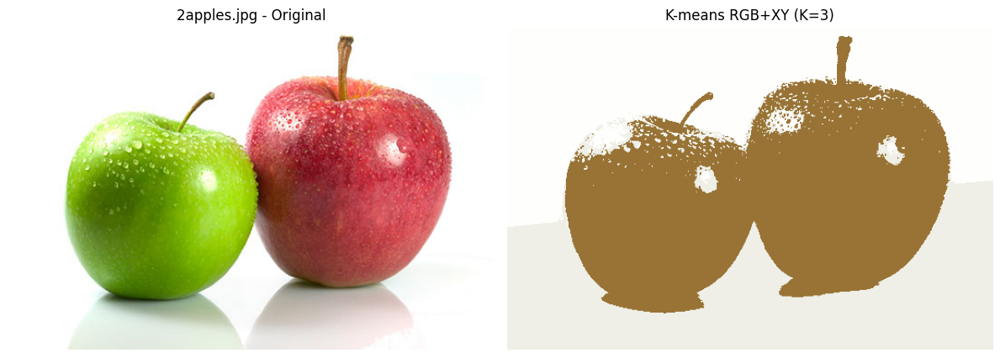


Processando 2or4objects.jpg com K = 5...
Peso espacial: 0.5
Iterações executadas: 12
Convergência atingida: True
Centroides RGB+XY encontrados:
Grupo 1: R=148.5, G=150.0, B=69.3, X=79.9, Y=77.6
Grupo 2: R=215.5, G=219.8, B=211.9, X=31.9, Y=89.4
Grupo 3: R=155.0, G=11.9, B=17.3, X=48.8, Y=66.8
Grupo 4: R=68.8, G=39.1, B=5.8, X=79.6, Y=62.0
Grupo 5: R=194.0, G=195.5, B=203.3, X=82.1, Y=25.0


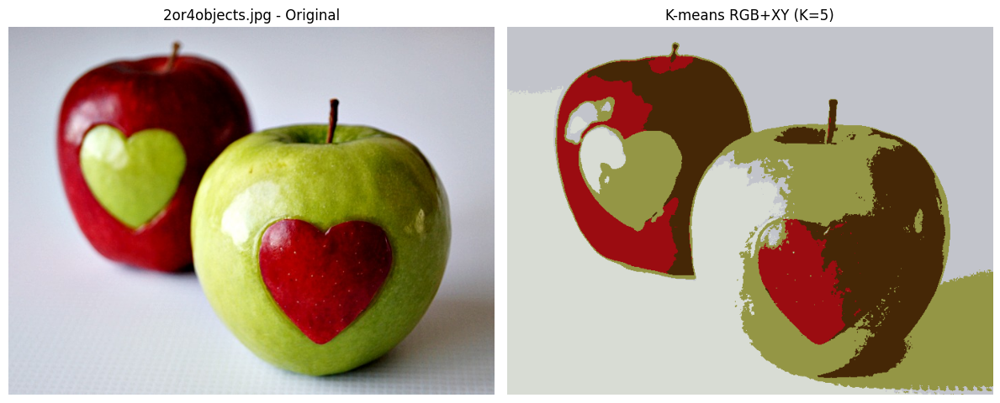

In [ ]:

# FUNÇÃO PARA EXECUTAR OS EXPERIMENTOS RGB+XY
# Aplica o K-means às imagens selecionadas, registra os
# parâmetros e apresenta os resultados de cada segmentação.

def executar_experimento_rgbxy(imagens, valores_k, peso_espacial):

    resultados = {}

    for nome, k in valores_k.items():

        print(f"\nProcessando {nome} com K = {k}...")
        print(f"Peso espacial: {peso_espacial}")

        # Executa a segmentação com os cinco atributos.
        resultado = segmentar_kmeans_rgbxy(
            imagens[nome],
            k=k,
            peso_espacial=peso_espacial
        )

        # Preserva os resultados e parâmetros da execução.
        resultados[nome] = resultado

        print(f"Iterações executadas: {resultado['iteracoes']}")
        print(f"Convergência atingida: {resultado['convergiu']}")

        print("Centroides RGB+XY encontrados:")

        # Exibe as cinco componentes de cada centroide.
        for indice, centroide in enumerate(resultado["centroides"]):

            print(
                f"Grupo {indice + 1}: "
                f"R={centroide[0]:.1f}, "
                f"G={centroide[1]:.1f}, "
                f"B={centroide[2]:.1f}, "
                f"X={centroide[3]:.1f}, "
                f"Y={centroide[4]:.1f}"
            )

        # Apresenta a imagem original e sua segmentação.
        exibir_resultado_kmeans_rgbxy(nome, resultado)

    return resultados


# CONFIGURAÇÃO INICIAL DO EXPERIMENTO
# Mantém os valores de K utilizados na segmentação RGB.
valores_k_5d = {
    "2apples.jpg": 3,
    "2or4objects.jpg": 5
}

PESO_ESPACIAL_INICIAL = 0.5

# Armazena separadamente os resultados do primeiro teste.
resultados_rgbxy_peso_05 = executar_experimento_rgbxy(
    imagens_originais,
    valores_k_5d,
    peso_espacial=PESO_ESPACIAL_INICIAL
)



### 4.2 Resultados da configuração inicial

A primeira execução do K-means RGB+XY utilizou um peso espacial de 0,5 para ambas as imagens.

**2apples.jpg — K = 3**

O algoritmo atingiu a convergência após 19 iterações. Entretanto, o resultado apresentou uma separação diferente da esperada.

As duas maçãs foram classificadas predominantemente no mesmo agrupamento, representado por uma tonalidade marrom, enquanto o fundo claro foi dividido em dois clusters.

Os centroides encontrados apresentaram as seguintes características:

- Grupo 1: RGB (152,1; 114,7; 53,2)
- Grupo 2: RGB (254,1; 253,8; 251,9)
- Grupo 3: RGB (239,4; 239,2; 231,4)

Observamos que dois centroides apresentaram valores RGB muito próximos das tonalidades claras do fundo, enquanto apenas um agrupamento representou a maior parte das maçãs.

**2or4objects.jpg — K = 5**

Na segunda imagem, o algoritmo convergiu após 12 iterações.

Os cinco agrupamentos conseguiram representar diferentes tonalidades das maçãs, dos corações e do fundo. Entretanto, algumas regiões pertencentes ao mesmo objeto foram divididas entre diferentes clusters, especialmente nas áreas de sombra e iluminação.

Diferentemente da primeira imagem, a segmentação preservou parte das diferenças cromáticas entre os objetos, embora ainda apresentasse fragmentações internas.



### 4.3 Identificação do problema

A análise da primeira configuração revelou que o peso espacial de 0,5 não produziu uma segmentação satisfatória para a imagem `2apples.jpg`.

Embora o K-means tenha atingido o critério de convergência, os agrupamentos não representaram adequadamente as diferenças cromáticas entre as maçãs.

Isso ocorreu porque as coordenadas X e Y passaram a exercer uma influência significativa sobre o cálculo das distâncias. Como consequência, o algoritmo favoreceu uma organização espacial que agrupou as duas maçãs, mesmo apresentando cores distintas, e dividiu o fundo em diferentes regiões.

Esse comportamento demonstrou que a convergência matemática do K-means não garante, necessariamente, uma segmentação visualmente adequada.

Identificamos, portanto, a necessidade de reduzir a influência das coordenadas espaciais para preservar melhor as diferenças entre as cores.

Para isso, decidimos testar uma segunda configuração, reduzindo o peso espacial de 0,5 para 0,25 e mantendo todos os demais parâmetros.



Processando 2apples.jpg com K = 3...
Peso espacial: 0.25
Iterações executadas: 57
Convergência atingida: True
Centroides RGB+XY encontrados:
Grupo 1: R=121.5, G=165.5, B=29.3, X=20.1, Y=37.7
Grupo 2: R=247.9, G=247.7, B=243.5, X=30.8, Y=30.5
Grupo 3: R=177.7, G=76.0, B=74.9, X=44.4, Y=30.9


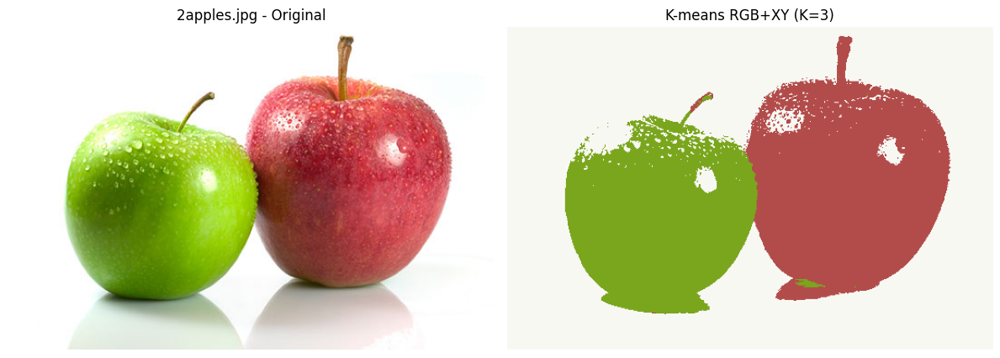


Processando 2or4objects.jpg com K = 5...
Peso espacial: 0.25
Iterações executadas: 11
Convergência atingida: True
Centroides RGB+XY encontrados:
Grupo 1: R=144.2, G=145.3, B=59.4, X=39.3, Y=37.4
Grupo 2: R=215.0, G=219.0, B=222.7, X=16.4, Y=41.4
Grupo 3: R=155.3, G=10.7, B=16.6, X=25.0, Y=34.1
Grupo 4: R=68.0, G=37.4, B=5.5, X=39.4, Y=30.7
Grupo 5: R=193.4, G=195.1, B=187.5, X=40.3, Y=19.1


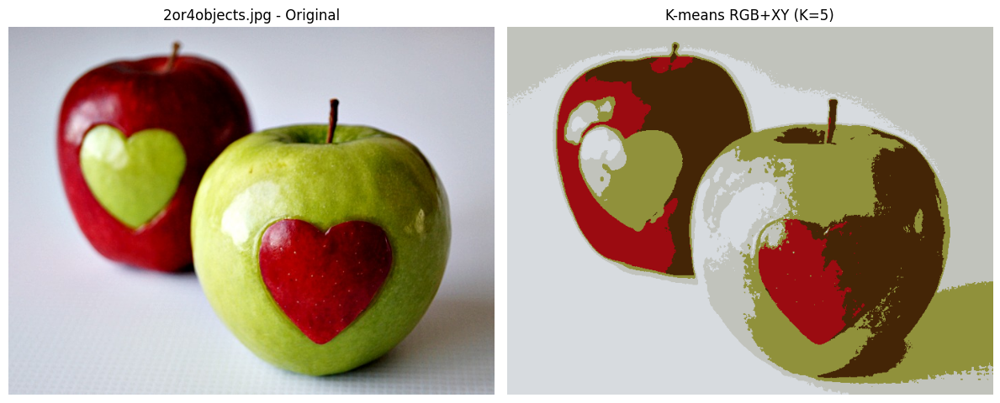

In [ ]:

# SEGUNDA CONFIGURAÇÃO DO K-MEANS RGB+XY
# Reduzimos o peso espacial para diminuir a influência
# das coordenadas X e Y sobre a classificação dos pixels.

PESO_ESPACIAL_AJUSTADO = 0.25

# Mantemos as mesmas imagens, valores de K, semente,
# tolerância e quantidade máxima de iterações.
# Dessa forma, isolamos o efeito da alteração do peso espacial.

resultados_rgbxy_peso_025 = executar_experimento_rgbxy(
    imagens_originais,
    valores_k_5d,
    peso_espacial=PESO_ESPACIAL_AJUSTADO
)



### 4.4 Resultados após o ajuste do peso espacial

Após identificar as limitações da primeira configuração, realizamos um segundo experimento utilizando peso espacial de 0,25.

O objetivo foi reduzir a influência das coordenadas X e Y, preservando sua participação no agrupamento, mas atribuindo maior importância relativa às diferenças cromáticas.

**2apples.jpg — K = 3**

Com o novo peso espacial, o algoritmo atingiu a convergência após 57 iterações.

Diferentemente da configuração inicial, os três agrupamentos passaram a representar adequadamente as principais regiões da imagem: a maçã verde, a maçã vermelha e o fundo claro.

Os centroides encontrados foram:

- Grupo 1: RGB (121,5; 165,5; 29,3) — região verde
- Grupo 2: RGB (247,9; 247,7; 243,5) — fundo claro
- Grupo 3: RGB (177,7; 76,0; 74,9) — região vermelha

O resultado demonstrou uma melhoria significativa na separação cromática das maçãs em comparação com o peso espacial de 0,5.

Entretanto, algumas regiões de brilho e reflexos continuaram sendo classificadas junto ao fundo, indicando que a segmentação ainda apresenta limitações nas áreas com variações intensas de iluminação.

**2or4objects.jpg — K = 5**

Na segunda imagem, o algoritmo convergiu após 11 iterações.

A segmentação preservou os principais agrupamentos cromáticos, distinguindo regiões vermelhas, esverdeadas, claras e sombreadas.

A redução do peso espacial modificou a distribuição dos clusters e a classificação de algumas regiões do fundo e dos objetos.

Entretanto, ainda observamos fragmentações internas nas maçãs, especialmente nas regiões com sombras e reflexos, demonstrando que a inclusão das coordenadas espaciais não elimina completamente os problemas causados pelas variações de cor.

### Considerações sobre o ajuste

Os experimentos demonstraram que o peso atribuído às coordenadas espaciais influencia diretamente o comportamento do K-means RGB+XY.

Com peso espacial de 0,5, a configuração não conseguiu separar adequadamente as duas maçãs da primeira imagem. Após a redução para 0,25, os agrupamentos passaram a representar melhor as diferenças cromáticas entre os objetos.

Dessa forma, selecionamos o peso espacial de 0,25 como configuração final do experimento, por apresentar um resultado mais equilibrado nas imagens analisadas.

A escolha demonstra que a inclusão das coordenadas espaciais pode contribuir para a organização dos agrupamentos, mas não garante uma melhoria automática na segmentação.

Os resultados finais serão comparados com a configuração RGB (3D), para avaliar as vantagens e limitações da utilização das cinco características.



## 5. Comparação entre K-means RGB (3D) e RGB+XY (5D)

### Justificativa da comparação

Após implementar as duas configurações do K-means, realizamos uma comparação visual para avaliar a influência da informação espacial na segmentação das imagens.

Na primeira configuração, RGB (3D), os pixels foram agrupados exclusivamente de acordo com suas características cromáticas. Na segunda configuração, RGB+XY (5D), acrescentamos as coordenadas espaciais X e Y, buscando favorecer a formação de agrupamentos mais localizados.

Para manter a consistência da comparação, utilizamos as mesmas imagens, os mesmos valores de K, a mesma semente aleatória e os mesmos critérios de convergência.

Na configuração RGB+XY, foi utilizado o peso espacial de 0,25, selecionado após os testes realizados anteriormente.

A comparação será apresentada por meio de três imagens lado a lado:

- **Imagem original:** referência para observar as características dos objetos.
- **K-means RGB (3D):** segmentação baseada exclusivamente nas cores.
- **K-means RGB+XY (5D):** segmentação considerando cor e posição espacial.

Também serão registrados os números de iterações necessários para a convergência de cada configuração.

O objetivo é identificar diferenças na separação dos objetos, na continuidade das regiões segmentadas, na classificação do fundo e na preservação dos detalhes presentes nas maçãs.

Essa comparação permitirá avaliar as vantagens e limitações de cada abordagem, considerando que a inclusão de informações espaciais não garante, necessariamente, uma segmentação mais precisa.


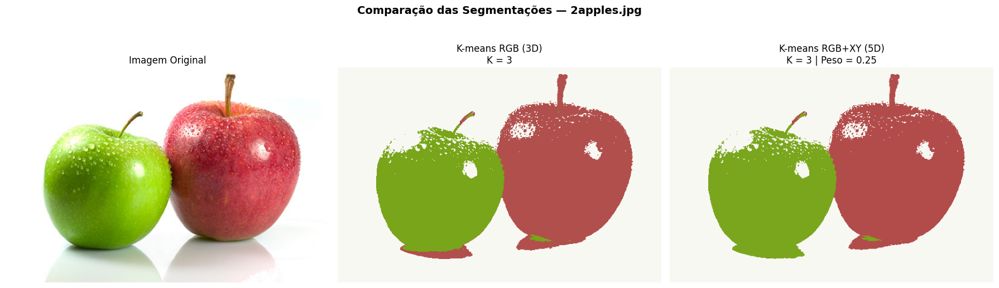


Resultados de 2apples.jpg:
RGB (3D): 68 iterações | Convergência: True
RGB+XY (5D): 57 iterações | Convergência: True


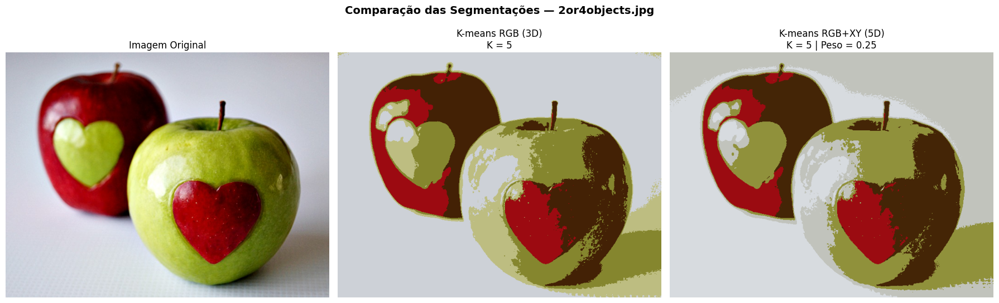


Resultados de 2or4objects.jpg:
RGB (3D): 31 iterações | Convergência: True
RGB+XY (5D): 11 iterações | Convergência: True


In [ ]:

# FUNÇÃO PARA COMPARAR AS CONFIGURAÇÕES DO K-MEANS
# Apresenta a imagem original e as segmentações RGB e RGB+XY,
# permitindo avaliar visualmente as diferenças entre os métodos.

def comparar_segmentacoes_kmeans(nome, resultado_rgb, resultado_rgbxy):

    # Recupera a imagem original e os resultados segmentados.
    original = resultado_rgb["original"]
    segmentada_rgb = resultado_rgb["segmentada"]
    segmentada_rgbxy = resultado_rgbxy["segmentada"]

    # Organiza as três imagens lado a lado para facilitar
    # a comparação entre os métodos.
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # IMAGEM ORIGINAL
    axes[0].imshow(original)
    axes[0].set_title("Imagem Original", fontsize=12)
    axes[0].axis("off")

    # SEGMENTAÇÃO RGB (3D)
    axes[1].imshow(segmentada_rgb)
    axes[1].set_title(
        f"K-means RGB (3D)\nK = {resultado_rgb['k']}",
        fontsize=12
    )
    axes[1].axis("off")

    # SEGMENTAÇÃO RGB+XY (5D)
    axes[2].imshow(segmentada_rgbxy)
    axes[2].set_title(
        f"K-means RGB+XY (5D)\n"
        f"K = {resultado_rgbxy['k']} | "
        f"Peso = {resultado_rgbxy['peso_espacial']}",
        fontsize=12
    )
    axes[2].axis("off")

    # Identifica a imagem utilizada na comparação.
    fig.suptitle(
        f"Comparação das Segmentações — {nome}",
        fontsize=14,
        fontweight="bold"
    )

    # Ajusta os espaços e exibe a comparação no Colab.
    plt.tight_layout()
    plt.show()

    # Registra os resultados de convergência das duas configurações.
    print(f"\nResultados de {nome}:")

    print(
        f"RGB (3D): {resultado_rgb['iteracoes']} iterações | "
        f"Convergência: {resultado_rgb['convergiu']}"
    )

    print(
        f"RGB+XY (5D): {resultado_rgbxy['iteracoes']} iterações | "
        f"Convergência: {resultado_rgbxy['convergiu']}"
    )


# EXECUÇÃO DA COMPARAÇÃO
# Utiliza os resultados já calculados nas etapas anteriores.

for nome in valores_k_5d.keys():

    comparar_segmentacoes_kmeans(
        nome,
        resultados_kmeans_rgb[nome],
        resultados_rgbxy_peso_025[nome]
    )



### 5.1 Análise comparativa dos resultados

A comparação entre as configurações RGB (3D) e RGB+XY (5D) permitiu avaliar a influência das coordenadas espaciais sobre os agrupamentos produzidos pelo K-means.

Para manter a consistência dos experimentos, utilizamos as mesmas imagens e valores de K, alterando apenas as características consideradas no cálculo das distâncias. Na configuração RGB+XY, foi utilizado o peso espacial ajustado para 0,25.

**2apples.jpg — K = 3**

Na primeira imagem, ambas as configurações conseguiram separar visualmente as três regiões cromáticas principais: a maçã verde, a maçã vermelha e o fundo claro.

O K-means RGB apresentou convergência após 68 iterações, enquanto o RGB+XY convergiu após 57 iterações.

Os resultados foram visualmente semelhantes, indicando que a inclusão das coordenadas espaciais não trouxe uma melhoria significativa na separação das maçãs. Entretanto, observamos pequenas diferenças próximas aos contornos inferiores dos objetos.

Em ambas as configurações, as regiões de brilho e reflexos continuaram apresentando classificações inadequadas, principalmente pela semelhança de suas tonalidades com o fundo claro.

**2or4objects.jpg — K = 5**

Na segunda imagem, as diferenças entre as configurações foram mais perceptíveis.

O K-means RGB convergiu após 31 iterações, enquanto o RGB+XY convergiu após 11 iterações.

Ambos os métodos conseguiram representar as principais regiões cromáticas das maçãs e dos corações. Entretanto, observamos diferenças na distribuição dos agrupamentos, especialmente no fundo, nos contornos e nas regiões de transição entre as cores.

Na configuração RGB+XY, a inclusão das coordenadas espaciais modificou a distribuição dos clusters, tornando algumas regiões mais localizadas. Contudo, também provocou divisões no fundo e não eliminou a fragmentação interna das maçãs.

As regiões de sombra e brilho continuaram sendo classificadas em agrupamentos diferentes, demonstrando que a informação espacial não foi suficiente para resolver todas as limitações da segmentação baseada em similaridade.

### 5.2 Discussão dos resultados

Os experimentos demonstraram que o K-means RGB apresenta bons resultados quando os objetos possuem diferenças cromáticas evidentes, como observado na imagem `2apples.jpg`.

A configuração RGB+XY acrescenta a localização dos pixels ao processo de agrupamento, permitindo considerar simultaneamente a similaridade das cores e a proximidade espacial.

Entretanto, verificamos que essa informação adicional não garante automaticamente uma segmentação superior.

O experimento inicial com peso espacial de 0,5 demonstrou que uma influência espacial excessiva pode comprometer a separação cromática. Após o ajuste para 0,25, os resultados apresentaram maior equilíbrio, preservando as principais diferenças de cor entre os objetos.

Embora o RGB+XY tenha atingido a convergência em menos iterações nas duas imagens, isso não permite afirmar que o método apresentou maior eficiência computacional, pois cada iteração envolve o processamento de cinco características, em vez de três.

Além disso, a convergência do algoritmo não representa necessariamente uma segmentação mais precisa. Ela indica apenas que os centroides atenderam ao critério de estabilização definido.

### 5.3 Conclusão do Projeto 1

A implementação das duas configurações do K-means permitiu compreender como diferentes características influenciam a segmentação de imagens.

O espaço RGB (3D) apresentou resultados satisfatórios na identificação das principais regiões cromáticas, especialmente quando havia contraste evidente entre os objetos e o fundo.

Já o espaço RGB+XY (5D) permitiu incorporar informações de localização, modificando a distribuição dos agrupamentos. Entretanto, sua eficácia mostrou-se dependente da ponderação espacial utilizada.

O ajuste experimental do peso de 0,5 para 0,25 foi fundamental para obter uma segmentação mais coerente na imagem `2apples.jpg`, demonstrando a importância da escolha dos parâmetros.

Concluímos que a inclusão das coordenadas espaciais não garante uma melhoria significativa em todas as situações. Nas imagens analisadas, o K-means RGB apresentou resultados competitivos, enquanto o RGB+XY exigiu maior cuidado no equilíbrio entre cor e localização.

Por fim, observamos que ambos os métodos apresentam limitações em regiões com reflexos, sombras e tonalidades semelhantes, pois a formação de clusters não corresponde necessariamente à separação individual dos objetos presentes na imagem.



# Projeto 2 — Segmentação de Rostos

## Implementação From Scratch

### Objetivo

Desenvolver e analisar métodos de segmentação de regiões de pele em imagens de rostos, implementando manualmente os algoritmos de limiarização por cor e crescimento de regiões.

O projeto será dividido em duas abordagens principais:

1. **Skin Color Thresholding:** identificação de regiões de pele por meio de condições estabelecidas sobre os valores dos pixels, comparando os espaços de cores RGB e HSV.

2. **Seeded Segmentation:** crescimento de regiões a partir de uma semente selecionada manualmente, considerando a similaridade entre os pixels vizinhos e a média das cores da região.

Os algoritmos principais serão implementados em Python, utilizando bibliotecas auxiliares para leitura, manipulação de matrizes, conversão de espaços de cores e visualização.

Ao final, serão discutidas as vantagens, limitações e possíveis métricas de avaliação das técnicas utilizadas.



## 1. Preparação e caracterização inicial das imagens

Antes de implementar os métodos de segmentação, realizamos o carregamento e a visualização das imagens de rostos disponibilizadas pelo professor.

O objetivo desta etapa é observar as características de cada imagem, considerando principalmente as diferenças de tonalidade da pele, iluminação, sombras e elementos presentes no fundo.

Essas características são importantes porque os algoritmos de segmentação baseados em cor dependem diretamente dos valores dos pixels, podendo apresentar resultados diferentes conforme as condições de iluminação e as semelhanças entre a pele e outras regiões da imagem.

As imagens serão carregadas utilizando OpenCV, mantendo suas dimensões e características originais. Para a visualização com Matplotlib, será realizada a conversão de BGR para RGB.



Imagem: face1.jpg
Dimensões: 1024 x 1024 pixels
Canais: 3
Total de pixels: 1048576

Imagem: face2.jpg
Dimensões: 712 x 800 pixels
Canais: 3
Total de pixels: 569600

Imagem: face3.jpeg
Dimensões: 1024 x 1024 pixels
Canais: 3
Total de pixels: 1048576

Imagem: face4.jpg
Dimensões: 400 x 600 pixels
Canais: 3
Total de pixels: 240000


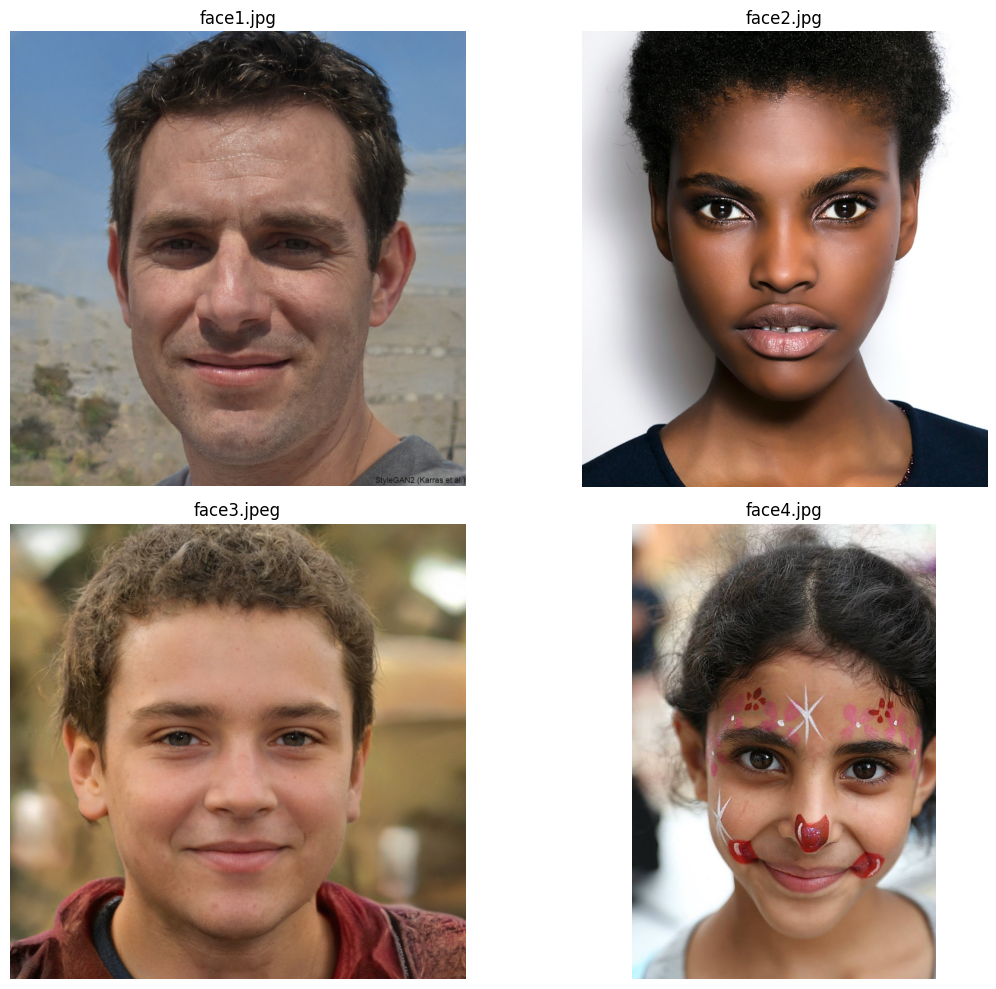

In [ ]:
# FUNÇÃO PARA CARREGAR AS IMAGENS
# Realiza a leitura dos arquivos presentes no Colab e
# armazena as imagens para utilização nas próximas etapas.

def carregar_imagens_rostos(nomes_arquivos):

    imagens = {}

    for nome in nomes_arquivos:

        # Realiza a leitura mantendo os três canais BGR.
        img = cv2.imread(
            f"/content/{nome}",
            cv2.IMREAD_COLOR
        )

        # Verifica se a imagem foi carregada corretamente.
        if img is None:
            print(f"Erro ao carregar: {nome}")
            continue

        # Armazena a imagem em suas dimensões originais.
        imagens[nome] = img

        altura, largura, canais = img.shape

        print(f"\nImagem: {nome}")
        print(f"Dimensões: {largura} x {altura} pixels")
        print(f"Canais: {canais}")
        print(f"Total de pixels: {largura * altura}")

    return imagens


# FUNÇÃO PARA EXIBIR AS IMAGENS
# Organiza as quatro imagens em uma grade 2x2, permitindo
# observar suas características antes da segmentação.

def exibir_imagens_rostos(imagens):

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # Organiza os eixos em uma lista para facilitar
    # a distribuição das imagens na grade.
    axes = axes.flatten()

    for indice, (nome, img) in enumerate(imagens.items()):

        # Converte BGR para RGB somente para visualização.
        img_rgb = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        axes[indice].imshow(img_rgb)
        axes[indice].set_title(nome, fontsize=12)
        axes[indice].axis("off")

    # Oculta os espaços não utilizados.
    for indice in range(len(imagens), len(axes)):
        axes[indice].axis("off")

    plt.tight_layout()
    plt.show()


# DEFINIÇÃO DAS IMAGENS DO PROJETO 2
# Utiliza os arquivos fornecidos pelo professor e
# disponibilizados diretamente na pasta do Colab.

nomes_rostos = [
    "face1.jpg",
    "face2.jpg",
    "face3.jpeg",
    "face4.jpg"
]

# Carrega e armazena as imagens originais.
imagens_rostos = carregar_imagens_rostos(nomes_rostos)

# Exibe as imagens para a caracterização inicial.
exibir_imagens_rostos(imagens_rostos)



## 2. Segmentação de pele por limiarização de cor

### Justificativa da escolha do método

Para identificar as regiões de pele nas imagens, utilizamos a técnica de limiarização por cor (Skin Color Thresholding), que classifica os pixels de acordo com condições estabelecidas sobre seus valores de cor.

A escolha do método foi fundamentada no artigo *Human Skin Detection Using RGB, HSV and YCbCr Color Models*, de Kolkur et al. (2017), indicado como referência no enunciado.

O artigo apresenta critérios de classificação de pixels de pele utilizando diferentes espaços de cores e destaca a influência da iluminação, das sombras e das variações de tonalidade sobre os resultados.

Neste experimento, implementaremos duas abordagens independentes, utilizando os critérios RGB e HSV apresentados na publicação como referência.

**Limiarização RGB**

No espaço RGB, cada pixel é representado pelas intensidades de vermelho (R), verde (G) e azul (B).

Utilizaremos as seguintes condições:

- R > 95
- G > 40
- B > 20
- R > G
- R > B
- |R - G| > 15

Um pixel será classificado como pele somente quando todas essas condições forem atendidas.

A principal limitação dessa abordagem está na influência da iluminação sobre os valores dos canais. Sombras e reflexos podem alterar as intensidades RGB e comprometer a identificação de algumas regiões.

**Limiarização HSV**

No espaço HSV, a cor é representada por três componentes:

- H (Hue): tonalidade da cor;
- S (Saturation): saturação;
- V (Value): intensidade ou brilho.

Para a classificação, utilizaremos os intervalos apresentados no artigo:

- 0° ≤ H ≤ 50°
- 0,23 ≤ S ≤ 0,68

Nesta configuração experimental, não estabeleceremos um limiar adicional para V, pois o objetivo é avaliar o comportamento dos critérios de tonalidade e saturação apresentados na referência.

Como o OpenCV utiliza escalas específicas para representar HSV, os valores serão convertidos para graus e saturação normalizada antes da aplicação dos limiares.

**Implementação From Scratch**

As condições de classificação serão implementadas manualmente em funções próprias, sem utilizar funções prontas de segmentação, como `cv2.inRange()`.

Para cada espaço de cores, será produzida uma máscara binária, na qual pixels brancos (255) representam regiões classificadas como pele e pixels pretos (0) representam regiões descartadas.

As máscaras também serão aplicadas às imagens originais para visualizar as regiões selecionadas.

**Resultados esperados**

Espera-se que os dois métodos consigam identificar parte significativa das regiões de pele presentes nas imagens.

Entretanto, poderão ocorrer classificações incorretas em áreas com sombras, iluminação intensa e objetos cujas cores sejam semelhantes às tonalidades de pele.

A comparação permitirá avaliar as diferenças entre os espaços RGB e HSV e discutir qual abordagem apresentou resultados visualmente mais adequados nas imagens analisadas.

É importante destacar que a identificação de pixels de pele não equivale necessariamente à detecção completa de rostos, pois outras regiões da imagem podem apresentar cores semelhantes.


In [ ]:

# FUNÇÃO PARA CLASSIFICAR PIXELS DE PELE NO ESPAÇO RGB
# Aplica as condições de limiarização estabelecidas a partir
# dos critérios apresentados por Kolkur et al. (2017).

def limiarizar_pele_rgb(img_rgb):

    # Separa os três canais da imagem e converte para int16.
    # A conversão evita problemas de estouro ao calcular
    # diferenças entre os valores dos canais.
    r = img_rgb[:, :, 0].astype(np.int16)
    g = img_rgb[:, :, 1].astype(np.int16)
    b = img_rgb[:, :, 2].astype(np.int16)

    # Verifica simultaneamente as condições de classificação.
    # Um pixel pertence à região de pele somente quando
    # todas as condições estabelecidas são verdadeiras.
    condicao_pele = (
        (r > 95) &
        (g > 40) &
        (b > 20) &
        (r > g) &
        (r > b) &
        (np.abs(r - g) > 15)
    )

    # Converte o resultado lógico em uma máscara binária.
    # Pixels classificados como pele recebem 255;
    # os demais recebem 0.
    mascara = condicao_pele.astype(np.uint8) * 255

    return mascara


# FUNÇÃO PARA CLASSIFICAR PIXELS DE PELE NO ESPAÇO HSV
# Utiliza intervalos de tonalidade e saturação fundamentados
# nos valores apresentados no artigo de referência.

def limiarizar_pele_hsv(img_hsv):

    # Recupera o canal H e converte sua escala de 0-179
    # para a representação aproximada em graus (0-360).
    h = img_hsv[:, :, 0].astype(np.float32) * 2.0

    # Normaliza a saturação para o intervalo entre 0 e 1.
    s = img_hsv[:, :, 1].astype(np.float32) / 255.0

    # Classifica os pixels que atendem simultaneamente
    # aos intervalos de tonalidade e saturação.
    condicao_pele = (
        (h >= 0.0) &
        (h <= 50.0) &
        (s >= 0.23) &
        (s <= 0.68)
    )

    # Constrói a máscara binária utilizando 0 e 255.
    mascara = condicao_pele.astype(np.uint8) * 255

    return mascara


# FUNÇÃO PARA APLICAR A MÁSCARA BINÁRIA
# Preserva as cores dos pixels classificados como pele
# e substitui as demais regiões por preto.

def aplicar_mascara_pele(img_rgb, mascara):

    # Cria uma imagem inicialmente preenchida com zeros.
    resultado = np.zeros_like(img_rgb)

    # Copia os pixels originais somente nas posições
    # em que a máscara apresenta valor igual a 255.
    resultado[mascara == 255] = img_rgb[mascara == 255]

    return resultado


# FUNÇÃO PARA EXECUTAR A SEGMENTAÇÃO NOS DOIS ESPAÇOS
# Realiza as conversões necessárias, aplica os limiares
# e armazena as máscaras e as imagens segmentadas.

def segmentar_pele_rgb_hsv(img_bgr):

    # Converte a imagem original BGR para RGB.
    img_rgb = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2RGB
    )

    # Converte a imagem original BGR para HSV.
    img_hsv = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2HSV
    )

    # Executa as duas implementações de limiarização.
    mascara_rgb = limiarizar_pele_rgb(img_rgb)
    mascara_hsv = limiarizar_pele_hsv(img_hsv)

    # Aplica cada máscara sobre a mesma imagem original.
    pele_rgb = aplicar_mascara_pele(img_rgb, mascara_rgb)
    pele_hsv = aplicar_mascara_pele(img_rgb, mascara_hsv)

    # Armazena os resultados de forma independente
    # para permitir comparações nas próximas etapas.
    return {
        "original": img_rgb,
        "mascara_rgb": mascara_rgb,
        "mascara_hsv": mascara_hsv,
        "pele_rgb": pele_rgb,
        "pele_hsv": pele_hsv
    }


# FUNÇÃO PARA EXIBIR OS RESULTADOS
# Organiza a imagem original, as máscaras binárias e
# as regiões classificadas como pele pelos dois métodos.

def exibir_segmentacao_pele(nome, resultado):

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    imagens = [
        resultado["original"],
        resultado["mascara_rgb"],
        resultado["pele_rgb"],
        resultado["mascara_hsv"],
        resultado["pele_hsv"]
    ]

    titulos = [
        "Imagem Original",
        "Máscara RGB",
        "Pele - RGB",
        "Máscara HSV",
        "Pele - HSV"
    ]

    for indice, img in enumerate(imagens):

        # Exibe as máscaras em escala de cinza e
        # as demais imagens utilizando suas cores originais.
        if indice in [1, 3]:
            axes[indice].imshow(
                img, cmap="gray", vmin=0, vmax=255
            )
        else:
            axes[indice].imshow(img)

        axes[indice].set_title(titulos[indice], fontsize=11)
        axes[indice].axis("off")

    fig.suptitle(
        f"Segmentação de Pele — {nome}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# FUNÇÃO PARA REGISTRAR A QUANTIDADE DE PIXELS SELECIONADOS
# Calcula o percentual de pixels classificados como pele
# em relação ao total de pixels da imagem.

def registrar_pixels_pele(nome, resultado):

    total_pixels = resultado["mascara_rgb"].size

    for metodo in ["rgb", "hsv"]:

        mascara = resultado[f"mascara_{metodo}"]

        # Conta os pixels brancos presentes na máscara.
        pixels_pele = np.count_nonzero(mascara)

        percentual = (pixels_pele / total_pixels) * 100

        print(
            f"{nome} | {metodo.upper()}: "
            f"{pixels_pele} pixels classificados como pele "
            f"({percentual:.2f}%)"
        )


# EXECUÇÃO DOS EXPERIMENTOS
# Aplica os dois métodos às quatro imagens de rostos
# disponibilizadas para o projeto.

resultados_limiarizacao = {}

for nome, img in imagens_rostos.items():

    print(f"\nProcessando {nome}...")

    resultado = segmentar_pele_rgb_hsv(img)

    # Preserva os resultados individuais de cada imagem.
    resultados_limiarizacao[nome] = resultado

    # Exibe as cinco representações para comparação.
    exibir_segmentacao_pele(nome, resultado)

    # Registra a quantidade de pixels selecionados.
    registrar_pixels_pele(nome, resultado)


Output hidden; open in https://colab.research.google.com to view.


### 2.1 Análise dos resultados — Limiarização RGB e HSV

A aplicação dos métodos de limiarização RGB e HSV permitiu identificar regiões com características cromáticas semelhantes às da pele humana nas quatro imagens disponibilizadas.

Os resultados demonstraram que ambos os métodos conseguem selecionar grande parte das regiões faciais, porém apresentaram diferenças na quantidade de pixels identificados e na classificação de elementos do fundo.

**face1.jpg**

Na primeira imagem, o método RGB classificou 37,71% dos pixels como pele, enquanto o HSV classificou 49,74%.

Ambos conseguiram identificar grande parte do rosto. Entretanto, o RGB apresentou uma máscara mais restritiva, preservando predominantemente a região facial, com algumas classificações incorretas no cenário.

O HSV identificou uma área maior, incluindo parte do cabelo e outras regiões do fundo que apresentavam características cromáticas dentro dos intervalos estabelecidos.

**face2.jpg**

Na segunda imagem, o RGB classificou 34,11% dos pixels como pele, enquanto o HSV classificou 45,05%.

O RGB conseguiu preservar grande parte da região facial e do pescoço, apresentando uma separação visual relativamente satisfatória em relação ao fundo.

O HSV também identificou essas regiões, porém apresentou uma quantidade maior de pixels classificados no cabelo e em algumas áreas escuras.

Em ambos os métodos, observamos falhas nas regiões dos olhos, sobrancelhas e boca, especialmente devido às diferenças de tonalidade, maquiagem e iluminação.

**face3.jpeg**

A terceira imagem apresentou os resultados mais problemáticos.

O RGB classificou 73,60% dos pixels como pele, enquanto o HSV classificou 89,78%.

Embora ambos tenham identificado a região facial, também classificaram grandes áreas do cenário como pele, principalmente devido à semelhança entre as tonalidades do fundo e os intervalos estabelecidos.

O HSV apresentou a maior quantidade de classificações indevidas, selecionando praticamente toda a imagem, com exceção de algumas regiões mais escuras.

Esse resultado demonstra uma limitação importante da limiarização baseada exclusivamente em cor: objetos e regiões do fundo podem apresentar valores semelhantes aos da pele humana, produzindo falsos positivos.

**face4.jpg**

Na quarta imagem, o RGB classificou 50,13% dos pixels como pele, enquanto o HSV classificou 52,45%.

Os dois métodos apresentaram resultados relativamente semelhantes, preservando grande parte do rosto, pescoço e ombros.

Entretanto, observamos falhas nas regiões com pinturas faciais, pois as cores aplicadas sobre a pele não atendem necessariamente aos critérios utilizados na classificação.

Também ocorreram classificações incorretas em algumas áreas do fundo, principalmente nas regiões com tonalidades próximas às da pele.

### 2.2 Comparação entre RGB e HSV

Os experimentos demonstraram que o espaço HSV não apresentou resultados necessariamente superiores ao RGB.

O RGB produziu máscaras visualmente mais seletivas em algumas imagens, especialmente nas situações em que o fundo apresentava diferenças cromáticas evidentes em relação à pele.

O HSV identificou uma quantidade maior de pixels em todas as imagens, mas essa característica não representou obrigatoriamente uma melhoria na segmentação, pois também aumentou a seleção de regiões que não correspondiam à pele.

A principal vantagem conceitual do HSV está na separação entre tonalidade, saturação e brilho, permitindo estabelecer critérios sobre características cromáticas sem depender diretamente do canal de intensidade.

Entretanto, essa separação não elimina os problemas causados por objetos com cores semelhantes à pele, iluminação irregular e variações de saturação.

Nas condições testadas, o RGB apresentou resultados visualmente mais seletivos em parte das imagens, enquanto o HSV apresentou maior abrangência, acompanhada de classificações incorretas mais extensas.

### 2.3 Considerações sobre os métodos

Os resultados confirmam que a limiarização por cor é uma técnica simples e útil para identificar regiões potencialmente correspondentes à pele, mas apresenta limitações quando utilizada isoladamente.

As máscaras produzidas não representam necessariamente a localização exata dos rostos, pois os algoritmos classificam cada pixel individualmente, sem considerar sua posição ou relação com os pixels vizinhos.

Também é importante destacar que os percentuais apresentados representam apenas a proporção de pixels classificados como pele, não sendo medidas de acurácia ou precisão.

Para avaliar quantitativamente a qualidade da segmentação, seria necessário comparar as máscaras obtidas com máscaras de referência previamente identificadas.

Dessa forma, não é possível estabelecer uma superioridade geral de um espaço de cores com base apenas nesses experimentos.

Concluímos que a escolha entre RGB e HSV depende das características das imagens e dos critérios de classificação utilizados. Nas imagens analisadas, o RGB apresentou resultados visualmente mais seletivos em algumas situações, enquanto o HSV frequentemente incluiu regiões adicionais do fundo.

Essas limitações reforçam a importância de investigar métodos que considerem também a relação espacial entre os pixels, como a segmentação por crescimento de regiões.

### 2.4 RGB é um bom espaço de cores ou HSV é melhor para segmentação de pele?

O espaço HSV apresenta vantagens teóricas para a segmentação de pele, pois separa a tonalidade (H) e a saturação (S) da intensidade luminosa (V), permitindo estabelecer critérios cromáticos com menor dependência direta do brilho.

Entretanto, os resultados obtidos demonstraram que o HSV não foi necessariamente superior ao RGB nas imagens analisadas.

O RGB apresentou máscaras visualmente mais seletivas em algumas imagens, enquanto o HSV identificou uma quantidade maior de pixels, incluindo também regiões do fundo e do cabelo classificadas incorretamente como pele.

Essa diferença ficou especialmente evidente na imagem `face3.jpeg`, em que o RGB classificou 73,60% dos pixels como pele, enquanto o HSV classificou 89,78%, abrangendo grande parte do cenário.

Portanto, embora o HSV ofereça uma representação cromática interessante para a segmentação, sua utilização não garante melhores resultados. A qualidade depende dos limiares estabelecidos, das condições de iluminação e das características da imagem.

Concluímos que, nas configurações testadas, o RGB apresentou resultados visualmente mais seletivos, enquanto o HSV mostrou maior abrangência, mas também maior inclusão de regiões indesejadas. Assim, não podemos afirmar que o HSV seja superior ao RGB para todas as situações.



## 3. Segmentação por crescimento de regiões (Seeded Segmentation)

### Justificativa da escolha do método

Após realizar a segmentação de pele por limiarização RGB e HSV, observamos que os métodos conseguiram identificar grande parte das regiões faciais, mas também apresentaram classificações incorretas em áreas do fundo com características cromáticas semelhantes às da pele.

Isso ocorre porque a limiarização classifica cada pixel individualmente, sem considerar sua relação espacial com os demais pixels da imagem.

Para investigar uma abordagem diferente, implementamos a segmentação por crescimento de regiões (Seeded Segmentation), conforme solicitado no enunciado.

O método parte de um pixel inicial, denominado semente, selecionado manualmente em uma região de pele do rosto. A partir dele, são analisados os pixels vizinhos, verificando sua similaridade com a média das cores dos pixels já incorporados à região.

Para essa implementação, utilizaremos uma vizinhança de quatro conexões, considerando os pixels localizados acima, abaixo, à esquerda e à direita de cada posição.

A similaridade será calculada pela diferença absoluta entre cada componente RGB do pixel candidato e a média correspondente da região.

Um pixel será incorporado somente quando as diferenças nos três canais permanecerem dentro da tolerância estabelecida.

Sempre que um novo pixel for incorporado, a média RGB da região será atualizada. Assim, o critério de comparação poderá acompanhar gradualmente as variações de tonalidade presentes na pele.

O crescimento será realizado por meio de uma fila, permitindo percorrer os pixels conectados sem depender de chamadas recursivas que poderiam ultrapassar o limite de recursão do Python em imagens grandes.

### Escolha dos parâmetros

Inicialmente, utilizaremos uma tolerância de 30 níveis de intensidade para cada canal RGB, considerando imagens de 8 bits, cujos valores variam entre 0 e 255.

Esse valor será utilizado como configuração experimental inicial, buscando permitir pequenas variações de tonalidade sem incorporar regiões excessivamente diferentes da cor média.

As sementes serão selecionadas manualmente em regiões de pele do rosto, preferencialmente nas bochechas, evitando áreas com sombras intensas, olhos, cabelo, maquiagem ou pinturas faciais.

### Resultados esperados

Espera-se obter regiões segmentadas espacialmente conectadas à semente inicial, reduzindo a seleção de objetos isolados do fundo que apresentam cores semelhantes à pele.

Entretanto, o crescimento poderá ser interrompido em regiões com diferenças de iluminação ou tonalidade superiores à tolerância estabelecida.

Também existe a possibilidade de a região se expandir para áreas indesejadas caso estas estejam conectadas à pele e apresentem cores suficientemente semelhantes.

Os resultados serão analisados para verificar a continuidade das regiões, a influência das sementes e as limitações do critério de tolerância.


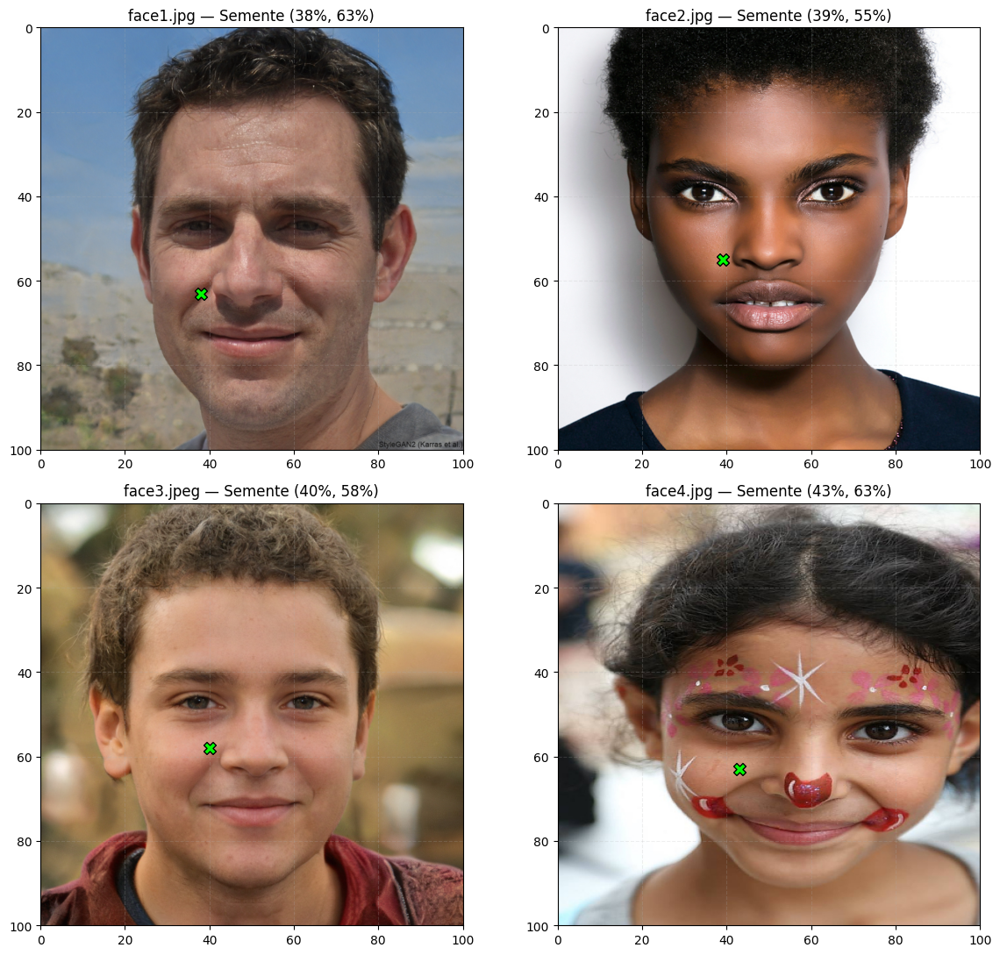

In [ ]:

# DEFINIÇÃO DAS SEMENTES
# As coordenadas são informadas em porcentagem da largura
# e da altura, considerando a origem no canto superior esquerdo.
# Os pontos são selecionados em regiões de pele das faces.

sementes_percentuais = {
    "face1.jpg": (38, 63),
    "face2.jpg": (39, 55),
    "face3.jpeg": (40, 58),
    "face4.jpg": (43, 63)
}


# FUNÇÃO PARA VISUALIZAR AS SEMENTES
# Apresenta os pontos definidos sobre as imagens originais,
# permitindo verificar sua localização antes do processamento.

def visualizar_sementes(imagens, sementes):

    fig, axes = plt.subplots(2, 2, figsize=(12, 11))
    axes = axes.flatten()

    for indice, (nome, img_bgr) in enumerate(imagens.items()):

        # Converte a imagem para RGB para visualização.
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Recupera a posição percentual da semente.
        x, y = sementes[nome]

        # Exibe a imagem com os eixos em porcentagem.
        axes[indice].imshow(
            img_rgb,
            extent=(0, 100, 100, 0)
        )

        # Marca a posição selecionada para iniciar o crescimento.
        axes[indice].scatter(
            x, y,
            color="lime",
            edgecolors="black",
            s=100,
            marker="X",
            zorder=5
        )

        axes[indice].set_title(
            f"{nome} — Semente ({x}%, {y}%)"
        )

        axes[indice].set_xticks(np.arange(0, 101, 20))
        axes[indice].set_yticks(np.arange(0, 101, 20))
        axes[indice].set_xlim(0, 100)
        axes[indice].set_ylim(100, 0)

        axes[indice].grid(
            True, alpha=0.2, linestyle="--"
        )

    plt.tight_layout()
    plt.show()


# EXIBIÇÃO DAS SEMENTES SELECIONADAS
visualizar_sementes(
    imagens_rostos,
    sementes_percentuais
)



Processando face1.jpg...


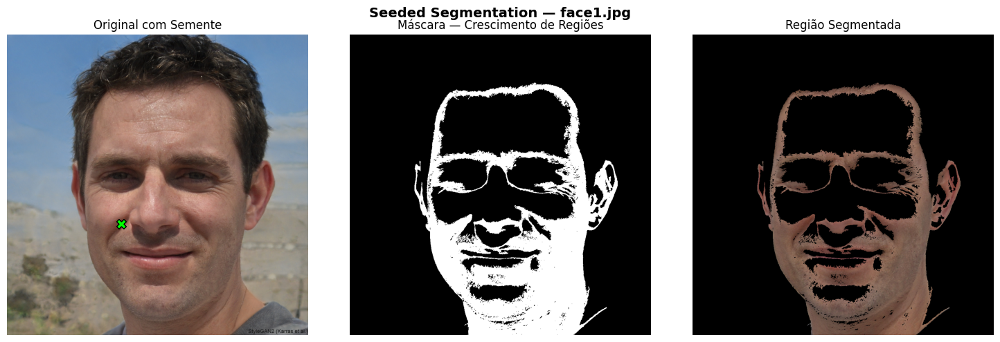

Semente utilizada: X=389, Y=644
Tolerância: 30
Pixels incorporados: 221550
Percentual da imagem: 21.13%

Processando face2.jpg...


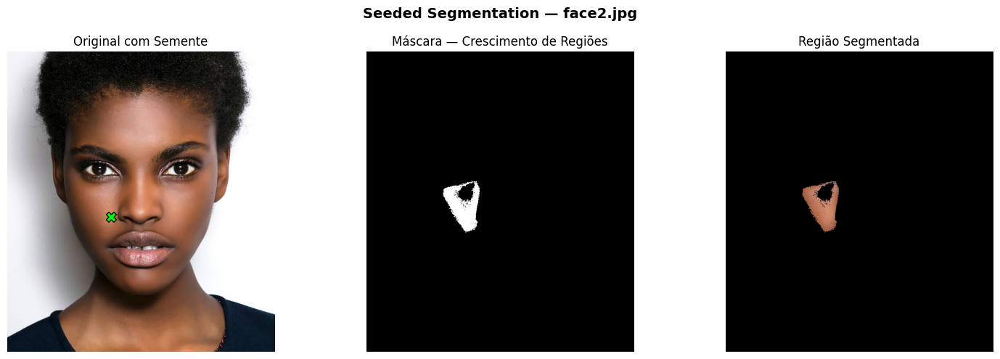

Semente utilizada: X=277, Y=439
Tolerância: 30
Pixels incorporados: 7052
Percentual da imagem: 1.24%

Processando face3.jpeg...


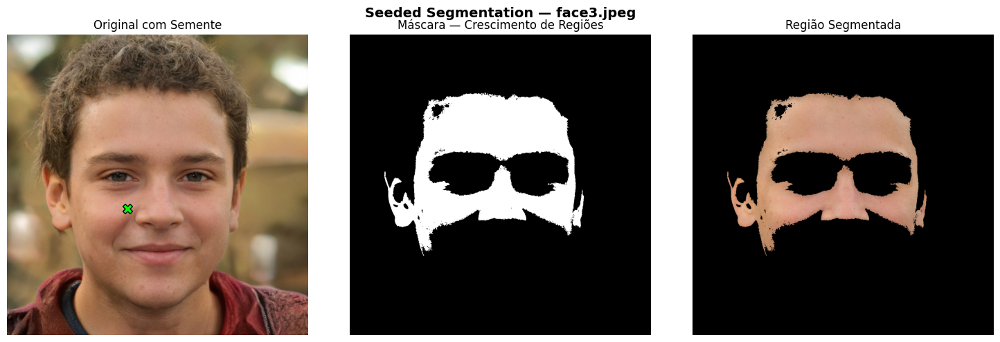

Semente utilizada: X=409, Y=593
Tolerância: 30
Pixels incorporados: 175532
Percentual da imagem: 16.74%

Processando face4.jpg...


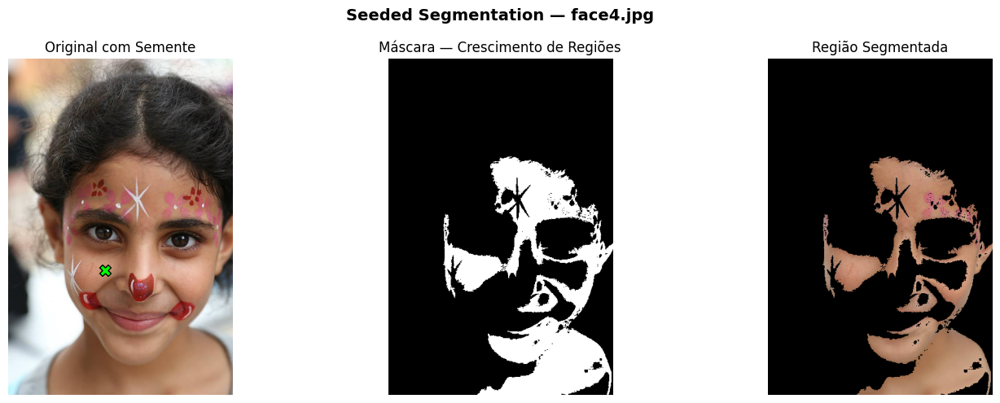

Semente utilizada: X=172, Y=377
Tolerância: 30
Pixels incorporados: 47564
Percentual da imagem: 19.82%


In [ ]:

from collections import deque


# FUNÇÃO PARA CONVERTER A SEMENTE EM COORDENADAS DE PIXEL
# Transforma a posição percentual em índices de coluna (X)
# e linha (Y), respeitando as dimensões da imagem.

def converter_semente(img, x_percentual, y_percentual):

    altura, largura = img.shape[:2]

    # Verifica se as coordenadas estão dentro da imagem.
    if not (0 <= x_percentual <= 100 and 0 <= y_percentual <= 100):
        raise ValueError("A semente deve estar entre 0% e 100%.")

    x = round((x_percentual / 100) * (largura - 1))
    y = round((y_percentual / 100) * (altura - 1))

    return int(x), int(y)


# FUNÇÃO PARA VERIFICAR A SIMILARIDADE DE COR
# Compara os canais RGB de um pixel candidato com
# a média atual dos pixels incorporados à região.

def verificar_similaridade(pixel, media_rgb, tolerancia):

    for canal in range(3):

        # Calcula a diferença absoluta entre o valor do
        # pixel e a média da região no canal correspondente.
        diferenca = abs(
            float(pixel[canal]) - media_rgb[canal]
        )

        # Rejeita o pixel quando qualquer componente
        # ultrapassa a tolerância estabelecida.
        if diferenca > tolerancia:
            return False

    return True


# FUNÇÃO DE CRESCIMENTO DE REGIÕES
# Expande a região a partir de uma semente, analisando
# a vizinhança-4 e atualizando continuamente a média RGB.

def crescimento_regioes(img_rgb, semente, tolerancia=30):

    altura, largura = img_rgb.shape[:2]

    x_inicial, y_inicial = semente

    # Verifica se a semente está dentro dos limites da imagem.
    if not (0 <= x_inicial < largura and 0 <= y_inicial < altura):
        raise ValueError("Semente fora dos limites da imagem.")

    if tolerancia < 0:
        raise ValueError("A tolerância não pode ser negativa.")

    # Cria a máscara binária que armazenará os pixels
    # incorporados à região durante o crescimento.
    mascara = np.zeros(
        (altura, largura),
        dtype=np.uint8
    )

    # Registra os pixels já analisados para evitar
    # que a mesma posição seja processada repetidamente.
    visitados = np.zeros(
        (altura, largura),
        dtype=np.uint8
    )

    # Inicializa a soma das cores com o pixel da semente.
    # A soma é armazenada em float para evitar overflow.
    soma_rgb = img_rgb[
        y_inicial, x_inicial
    ].astype(np.float64)

    quantidade_pixels = 1

    # Inclui a semente na região e marca sua posição.
    mascara[y_inicial, x_inicial] = 255
    visitados[y_inicial, x_inicial] = 1

    # Inicia a fila com o ponto de semente.
    fila = deque([(x_inicial, y_inicial)])

    # Define a vizinhança de quatro conexões:
    # direita, esquerda, abaixo e acima.
    vizinhos = [
        (1, 0),
        (-1, 0),
        (0, 1),
        (0, -1)
    ]

    # Percorre a fila até não existirem novos pixels
    # conectados que atendam ao critério de similaridade.
    while fila:

        x_atual, y_atual = fila.popleft()

        # Calcula a média atualizada da região.
        media_rgb = soma_rgb / quantidade_pixels

        # Verifica os quatro vizinhos do pixel atual.
        for deslocamento_x, deslocamento_y in vizinhos:

            novo_x = x_atual + deslocamento_x
            novo_y = y_atual + deslocamento_y

            # Desconsidera posições fora da imagem.
            if not (0 <= novo_x < largura and 0 <= novo_y < altura):
                continue

            # Desconsidera pixels já analisados.
            if visitados[novo_y, novo_x] == 1:
                continue

            # Marca o pixel como visitado antes da comparação.
            visitados[novo_y, novo_x] = 1

            # Recupera a cor do pixel candidato.
            pixel = img_rgb[novo_y, novo_x]

            # Verifica a similaridade com a média da região.
            if verificar_similaridade(
                pixel, media_rgb, tolerancia
            ):

                # Incorpora o pixel à máscara segmentada.
                mascara[novo_y, novo_x] = 255

                # Atualiza a soma dos canais RGB.
                soma_rgb += pixel.astype(np.float64)

                # Atualiza a quantidade de pixels da região.
                quantidade_pixels += 1

                # Adiciona o pixel à fila para que seus
                # próprios vizinhos também sejam analisados.
                fila.append((novo_x, novo_y))

    return mascara, quantidade_pixels


# FUNÇÃO PARA EXECUTAR A SEGMENTAÇÃO SEMEADA
# Converte as coordenadas, executa o crescimento e aplica
# a máscara obtida sobre a imagem original.

def segmentar_rosto_semente(
    img_bgr, semente_percentual, tolerancia=30
):

    # Converte a imagem original para o espaço RGB.
    img_rgb = cv2.cvtColor(
        img_bgr, cv2.COLOR_BGR2RGB
    )

    # Converte a semente percentual para coordenadas de pixel.
    semente = converter_semente(
        img_rgb,
        semente_percentual[0],
        semente_percentual[1]
    )

    # Executa o crescimento de regiões.
    mascara, quantidade = crescimento_regioes(
        img_rgb,
        semente,
        tolerancia
    )

    # Preserva as cores apenas dos pixels incorporados
    # à região segmentada.
    img_segmentada = np.zeros_like(img_rgb)
    img_segmentada[mascara == 255] = img_rgb[mascara == 255]

    return {
        "original": img_rgb,
        "mascara": mascara,
        "segmentada": img_segmentada,
        "semente": semente,
        "tolerancia": tolerancia,
        "pixels_regiao": quantidade
    }


# FUNÇÃO PARA EXIBIR A SEGMENTAÇÃO SEMEADA
# Apresenta a posição da semente, a máscara binária
# e o resultado do crescimento de regiões.

def exibir_resultado_semeado(nome, resultado):

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # IMAGEM ORIGINAL
    axes[0].imshow(resultado["original"])

    x, y = resultado["semente"]

    # Marca a semente utilizada na execução.
    axes[0].scatter(
        x, y,
        color="lime",
        edgecolors="black",
        marker="X",
        s=100
    )

    axes[0].set_title("Original com Semente")
    axes[0].axis("off")

    # MÁSCARA BINÁRIA
    axes[1].imshow(
        resultado["mascara"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[1].set_title("Máscara — Crescimento de Regiões")
    axes[1].axis("off")

    # IMAGEM SEGMENTADA
    axes[2].imshow(resultado["segmentada"])
    axes[2].set_title("Região Segmentada")
    axes[2].axis("off")

    fig.suptitle(
        f"Seeded Segmentation — {nome}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# EXECUÇÃO DOS EXPERIMENTOS
# Utiliza a mesma tolerância inicial para as quatro imagens.

TOLERANCIA_INICIAL = 30

resultados_semeados = {}

for nome, img in imagens_rostos.items():

    print(f"\nProcessando {nome}...")

    resultado = segmentar_rosto_semente(
        img,
        sementes_percentuais[nome],
        tolerancia=TOLERANCIA_INICIAL
    )

    resultados_semeados[nome] = resultado

    # Apresenta a segmentação realizada.
    exibir_resultado_semeado(nome, resultado)

    # Registra a semente e o tamanho da região encontrada.
    x, y = resultado["semente"]

    percentual = (
        resultado["pixels_regiao"] /
        resultado["mascara"].size
    ) * 100

    print(f"Semente utilizada: X={x}, Y={y}")
    print(f"Tolerância: {resultado['tolerancia']}")
    print(f"Pixels incorporados: {resultado['pixels_regiao']}")
    print(f"Percentual da imagem: {percentual:.2f}%")



### 3.1 Avaliação da tolerância no crescimento de regiões

A primeira execução do algoritmo utilizou uma tolerância de 30 níveis de intensidade para cada canal RGB.

Embora o crescimento tenha identificado regiões de pele nas quatro imagens, observamos que a segmentação apresentou limitações significativas, especialmente na imagem `face2.jpg`, em que apenas 1,24% dos pixels foram incorporados à região.

Esse resultado indica que o critério de similaridade pode estar excessivamente restritivo, impedindo que o crescimento alcance regiões do rosto com variações de tonalidade e iluminação.

Para investigar essa hipótese, realizaremos um experimento com tolerâncias de 30, 45 e 60, mantendo a mesma imagem, semente e algoritmo.

O objetivo é observar como o aumento da tolerância influencia a extensão da região segmentada, avaliando tanto a recuperação de regiões de pele quanto o risco de incorporar pixels indesejados.


Tolerância 30: 7052 pixels (1.24%)
Tolerância 45: 76075 pixels (13.36%)
Tolerância 60: 174137 pixels (30.57%)


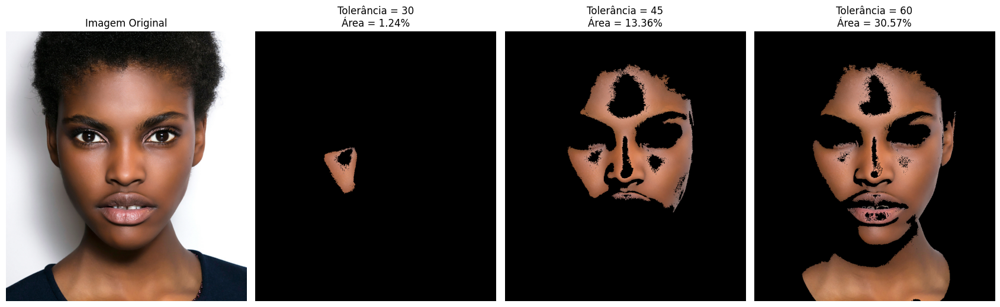

In [ ]:

# FUNÇÃO PARA COMPARAR DIFERENTES TOLERÂNCIAS
# Executa o crescimento de regiões com diferentes valores,
# mantendo a mesma imagem e a mesma semente inicial.

def comparar_tolerancias(nome, imagem, semente, tolerancias):

    resultados = {}

    # Organiza os resultados em uma única linha para comparar
    # a extensão das regiões obtidas em cada configuração.
    fig, axes = plt.subplots(
        1, len(tolerancias) + 1,
        figsize=(17, 5)
    )

    # Exibe a imagem original como referência.
    img_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

    axes[0].imshow(img_rgb)
    axes[0].set_title("Imagem Original")
    axes[0].axis("off")

    for indice, tolerancia in enumerate(tolerancias):

        # Reutiliza o resultado inicial quando disponível,
        # evitando executar novamente a tolerância de 30.
        if (
            tolerancia == TOLERANCIA_INICIAL
            and nome in resultados_semeados
        ):
            resultado = resultados_semeados[nome]

        else:
            # Executa o crescimento utilizando a nova tolerância.
            resultado = segmentar_rosto_semente(
                imagem,
                semente,
                tolerancia=tolerancia
            )

        # Armazena cada experimento separadamente.
        resultados[tolerancia] = resultado

        # Calcula a proporção da imagem incorporada à região.
        percentual = (
            resultado["pixels_regiao"] /
            resultado["mascara"].size
        ) * 100

        # Exibe a região segmentada para comparação.
        axes[indice + 1].imshow(resultado["segmentada"])

        axes[indice + 1].set_title(
            f"Tolerância = {tolerancia}\n"
            f"Área = {percentual:.2f}%"
        )

        axes[indice + 1].axis("off")

        print(
            f"Tolerância {tolerancia}: "
            f"{resultado['pixels_regiao']} pixels "
            f"({percentual:.2f}%)"
        )

    plt.tight_layout()
    plt.show()

    return resultados


# TESTE DE TOLERÂNCIAS NA IMAGEM FACE2
# Mantém a semente previamente definida e altera
# exclusivamente o parâmetro de tolerância.

tolerancias_teste = [30, 45, 60]

resultados_tolerancias_face2 = comparar_tolerancias(
    "face2.jpg",
    imagens_rostos["face2.jpg"],
    sementes_percentuais["face2.jpg"],
    tolerancias_teste
)


### 3.2 Ajuste experimental da tolerância

O experimento realizado na imagem `face2.jpg` mostrou que a tolerância inicial de 30 foi excessivamente restritiva, limitando o crescimento da região a uma pequena área próxima à semente.

Ao comparar os valores 30, 45 e 60, observamos que o aumento da tolerância permitiu incorporar uma área maior da face, acompanhando melhor as variações de tonalidade e iluminação da pele.

A tolerância 60 apresentou o resultado mais satisfatório no experimento, segmentando uma porção significativamente maior do rosto sem expandir de forma descontrolada para toda a imagem.

Com base nesse resultado, realizaremos uma nova execução do algoritmo nas quatro imagens, utilizando tolerância igual a 60.

O objetivo é verificar se esse ajuste melhora a segmentação de forma geral, mantendo a mesma lógica do algoritmo, a mesma vizinhança e as mesmas sementes selecionadas anteriormente.


Processando face1.jpg...


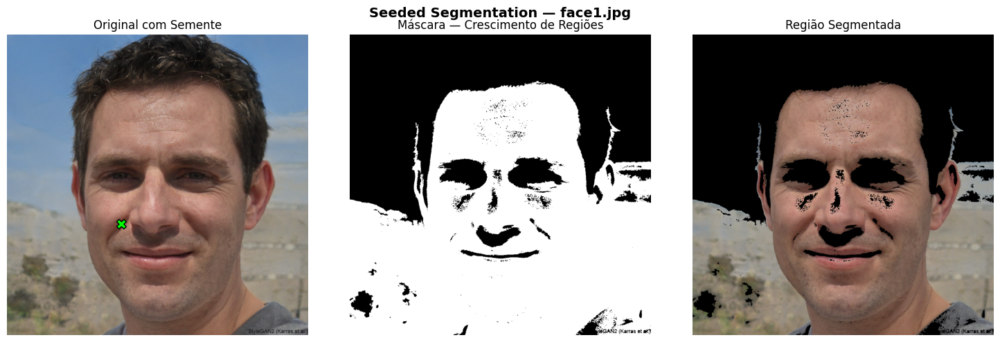

Semente utilizada: X=389, Y=644
Tolerância: 60
Pixels incorporados: 625320
Percentual da imagem: 59.64%

Processando face2.jpg...


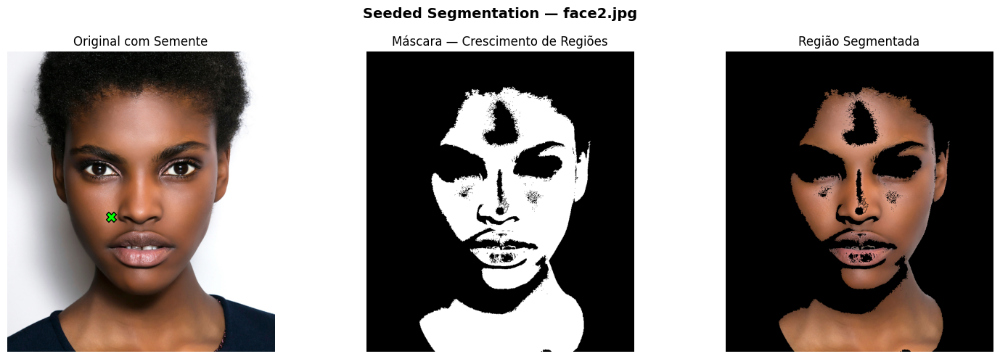

Semente utilizada: X=277, Y=439
Tolerância: 60
Pixels incorporados: 174137
Percentual da imagem: 30.57%

Processando face3.jpeg...


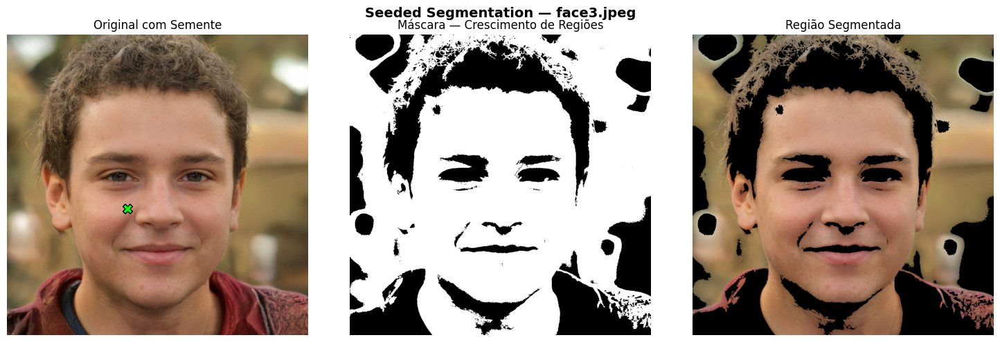

Semente utilizada: X=409, Y=593
Tolerância: 60
Pixels incorporados: 729606
Percentual da imagem: 69.58%

Processando face4.jpg...


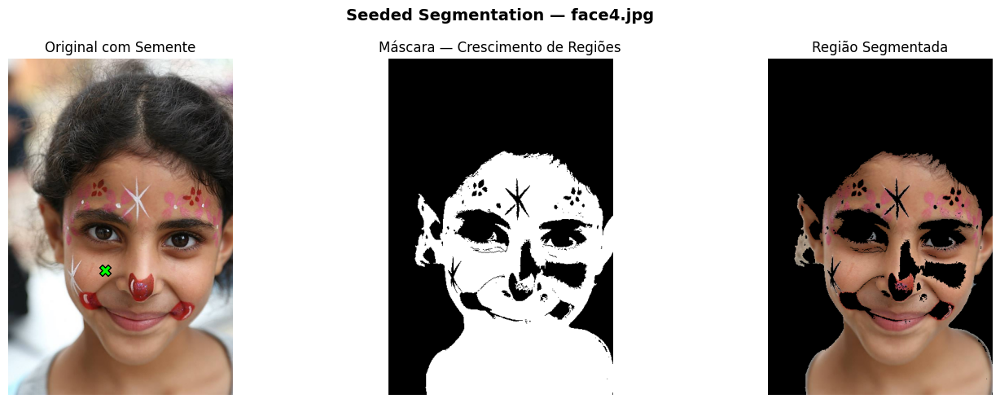

Semente utilizada: X=172, Y=377
Tolerância: 60
Pixels incorporados: 98058
Percentual da imagem: 40.86%


In [ ]:
# NOVA CONFIGURAÇÃO GLOBAL
# Reexecuta a segmentação semeada nas quatro imagens
# utilizando a tolerância ajustada a partir do experimento.

TOLERANCIA_AJUSTADA = 60

resultados_semeados_t60 = {}

for nome, img in imagens_rostos.items():

    print(f"\nProcessando {nome}...")

    resultado = segmentar_rosto_semente(
        img,
        sementes_percentuais[nome],
        tolerancia=TOLERANCIA_AJUSTADA
    )

    resultados_semeados_t60[nome] = resultado

    exibir_resultado_semeado(nome, resultado)

    x, y = resultado["semente"]

    percentual = (
        resultado["pixels_regiao"] /
        resultado["mascara"].size
    ) * 100

    print(f"Semente utilizada: X={x}, Y={y}")
    print(f"Tolerância: {resultado['tolerancia']}")
    print(f"Pixels incorporados: {resultado['pixels_regiao']}")
    print(f"Percentual da imagem: {percentual:.2f}%")

### 3.3 Análise dos resultados — Segmentação semeada

A segmentação por crescimento de regiões foi inicialmente executada com tolerância igual a 30. Embora o algoritmo tenha funcionado corretamente, os resultados mostraram que essa configuração era excessivamente restritiva em parte das imagens, impedindo que o crescimento alcançasse regiões maiores do rosto.

A limitação ficou especialmente evidente na imagem `face2.jpg`, em que apenas 1,24% dos pixels foram incorporados à região. Esse comportamento indicou que pequenas variações de tonalidade e iluminação já eram suficientes para interromper a expansão da região segmentada.

Para investigar o efeito da tolerância, foi realizado um experimento adicional na imagem `face2.jpg`, comparando os valores 30, 45 e 60. O resultado mostrou que o aumento da tolerância permitiu ampliar significativamente a região segmentada, sendo a tolerância 60 a que apresentou o melhor equilíbrio entre extensão da face segmentada e continuidade da região.

Com base nesse experimento, o algoritmo foi executado novamente nas quatro imagens com tolerância igual a 60.

**face1.jpg**

Na primeira imagem, a segmentação passou a abranger uma porção muito maior do rosto em comparação à execução inicial. O crescimento também alcançou o pescoço e regiões próximas ao fundo, demonstrando que a tolerância mais alta favoreceu a continuidade da região, mas também aumentou a incorporação de áreas externas conectadas à pele.

A região segmentada correspondeu a 59,64% da imagem.

**face2.jpg**

Na segunda imagem, a mudança foi bastante significativa. A tolerância 60 permitiu que o crescimento alcançasse grande parte da face e do pescoço, superando claramente o resultado obtido com tolerância 30.

A região segmentada correspondeu a 30,57% da imagem.

Esse resultado confirmou que a tolerância inicial estava muito baixa para acompanhar as variações tonais da pele presentes nessa imagem.

**face3.jpeg**

Na terceira imagem, o algoritmo passou a segmentar uma área bastante ampla da face, cobrindo grande parte da testa, bochechas e região central do rosto.

Entretanto, o crescimento também incorporou regiões externas, indicando que a tolerância 60 se tornou relativamente permissiva para essa imagem.

A região segmentada correspondeu a 69,58% da imagem.

**face4.jpg**

Na quarta imagem, o crescimento de regiões também apresentou melhora em relação à execução inicial, segmentando uma área maior da face.

Mesmo assim, o resultado continuou sendo fortemente influenciado pelas pinturas faciais, que alteram significativamente as cores da pele e dificultam a continuidade do crescimento.

A região segmentada correspondeu a 40,86% da imagem.

### 3.4 Discussão do método

Os resultados demonstraram que a segmentação semeada apresenta uma vantagem importante em relação à limiarização por cor: o crescimento ocorre a partir de uma região conectada, reduzindo a seleção de objetos isolados do fundo que possuam cores semelhantes à pele.

Por outro lado, o método depende fortemente da escolha da semente e do valor de tolerância.

Quando a tolerância foi muito baixa, o crescimento ficou excessivamente restrito. Quando aumentamos a tolerância, o algoritmo conseguiu acompanhar melhor as variações naturais da pele, mas também passou a incorporar regiões indesejadas.

Outro aspecto importante é que a implementação compara cada pixel candidato com a média atual da região. Isso permite adaptar o crescimento gradualmente, mas também pode favorecer a incorporação de pixels externos quando suas cores permanecem suficientemente próximas dessa média.

Além disso, cada pixel candidato é avaliado apenas uma vez. Assim, um pixel rejeitado em um momento inicial não é reavaliado posteriormente, mesmo que a média da região se altere durante o crescimento. Essa característica também influencia os resultados obtidos.

### 3.5 Conclusão da segmentação semeada

A segmentação por crescimento de regiões mostrou-se capaz de identificar regiões faciais conectadas de forma mais controlada do que a limiarização baseada apenas em cor.

Entretanto, os experimentos demonstraram que seu desempenho depende diretamente da escolha da semente e do ajuste da tolerância.

A tolerância 60 apresentou resultados globalmente mais satisfatórios do que a tolerância 30, permitindo segmentar regiões faciais mais amplas nas quatro imagens analisadas.

Mesmo assim, o método continuou sujeito a erros em áreas com sombras, pinturas faciais, diferenças intensas de iluminação e regiões do fundo conectadas à pele.

Portanto, a segmentação semeada apresentou vantagens em termos de conectividade espacial, mas não eliminou completamente as limitações observadas na segmentação de pele.


## 4. Métricas de avaliação e conclusão

### 4.1 Métricas de avaliação

Para avaliar quantitativamente a qualidade dos métodos de segmentação, podemos comparar as máscaras produzidas pelos algoritmos com máscaras de referência (Ground Truth), que representam as regiões corretamente identificadas.

Essa comparação permite identificar:

- **Verdadeiros Positivos (TP):** pixels de pele corretamente identificados.
- **Falsos Positivos (FP):** pixels de outras regiões classificados como pele.
- **Falsos Negativos (FN):** pixels de pele não identificados.
- **Verdadeiros Negativos (TN):** pixels de outras regiões corretamente descartados.

A partir dessas informações, podemos utilizar as seguintes métricas:

**Precisão (Precision):** indica a proporção de pixels classificados como pele que realmente pertencem à região desejada.

$$
Precision = \frac{TP}{TP+FP}
$$

**Revocação (Recall):** indica a proporção dos pixels de pele que foram corretamente identificados.

$$
Recall = \frac{TP}{TP+FN}
$$

**Acurácia (Accuracy):** representa a proporção total de pixels classificados corretamente.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

**Intersection over Union (IoU):** mede a sobreposição entre a máscara segmentada e a máscara de referência.

$$
IoU = \frac{TP}{TP+FP+FN}
$$

**Coeficiente Dice:** também mede a sobreposição entre duas máscaras, atribuindo maior peso aos pixels corretamente identificados na região de interesse.

$$
Dice = \frac{2TP}{2TP+FP+FN}
$$

Para nosso projeto, consideramos **IoU, Dice, Precision e Recall** especialmente adequadas, pois permitiriam avaliar tanto a preservação das regiões faciais quanto a incorporação incorreta de áreas externas.

Essas métricas podem ser aplicadas diretamente aos métodos tradicionais de segmentação, sem necessidade de utilizar Deep Learning.

Entretanto, não dispomos de máscaras Ground Truth para as quatro imagens utilizadas. Por esse motivo, a avaliação realizada foi qualitativa, baseada na observação das máscaras e na comparação visual dos resultados.

Os percentuais de pixels segmentados apresentados anteriormente não representam medidas de precisão ou acurácia.

### 4.2 Conclusão do Projeto 2

A implementação dos métodos de limiarização RGB, HSV e crescimento de regiões permitiu observar diferentes abordagens para identificar regiões de pele em imagens.

Na limiarização, o RGB apresentou resultados visualmente mais seletivos em algumas situações, enquanto o HSV identificou uma quantidade maior de pixels, incluindo também regiões indesejadas do fundo.

Já o crescimento de regiões demonstrou a importância da conectividade espacial, mas apresentou forte dependência da escolha da semente e da tolerância utilizada.

O ajuste da tolerância de 30 para 60 permitiu ampliar as regiões faciais segmentadas, embora também tenha favorecido a incorporação de áreas externas em algumas imagens.

Concluímos que nenhum dos métodos apresentou resultados superiores em todas as situações. A qualidade da segmentação depende das características da imagem, dos critérios de similaridade e dos parâmetros utilizados.

Os experimentos também demonstraram que identificar uma quantidade maior de pixels não significa necessariamente obter uma segmentação mais precisa.



# Morfologia — Opção 1: Segmentação K-means

## 1. Conversão dos agrupamentos em máscaras binárias

### Justificativa da implementação

Após realizar a segmentação das imagens utilizando K-means RGB (3D) e RGB+XY (5D), iniciaremos o processamento morfológico dos resultados obtidos.

As operações morfológicas serão aplicadas sobre máscaras binárias, permitindo analisar e modificar a estrutura espacial das regiões segmentadas.

Para isso, precisamos converter os agrupamentos produzidos pelo K-means em imagens binárias, nas quais:

- **Branco (255):** representa os pixels pertencentes ao agrupamento selecionado.
- **Preto (0):** representa os demais pixels da imagem.

Inicialmente, serão geradas máscaras individuais para cada cluster, tanto na configuração RGB quanto na RGB+XY.

Essa visualização permitirá identificar quais agrupamentos correspondem às regiões das maçãs e quais representam predominantemente o fundo.

A análise individual dos clusters é necessária porque o K-means agrupa pixels por similaridade de características, não garantindo que cada agrupamento corresponda a um objeto completo.

Na imagem `2or4objects.jpg`, por exemplo, diferentes tonalidades de iluminação e sombra podem fazer com que uma mesma maçã seja dividida entre vários clusters.

Após identificar os agrupamentos relevantes, poderemos construir as máscaras das regiões de interesse que serão utilizadas nas operações morfológicas.

Nesta etapa, não serão aplicadas operações de erosão, dilatação, abertura ou fechamento. O objetivo é apenas preparar e analisar as máscaras produzidas a partir da segmentação original.


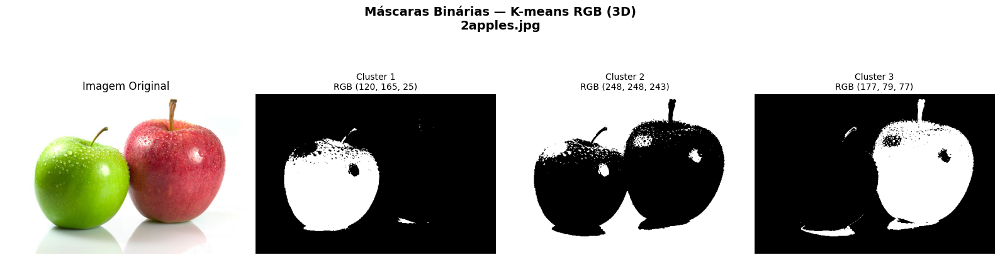

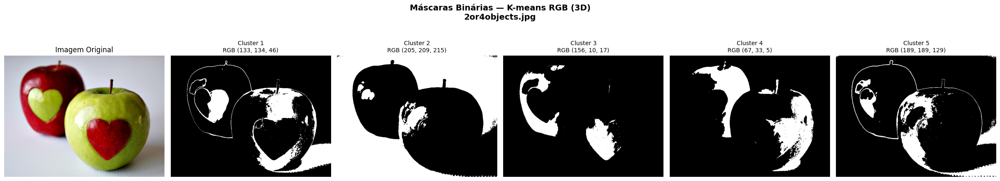

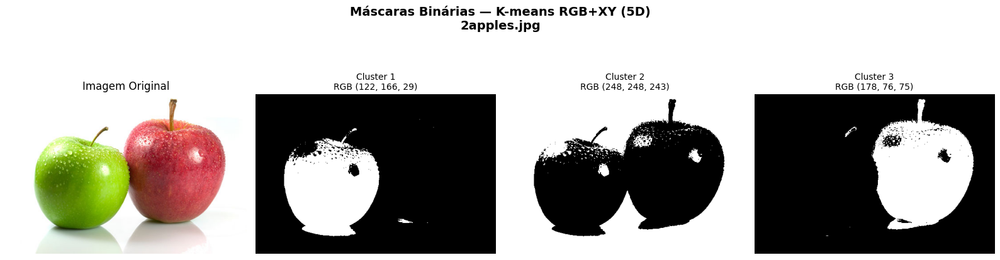

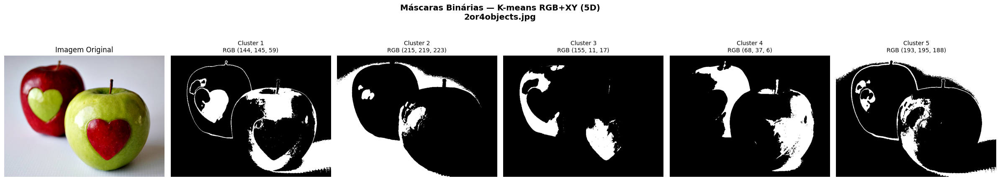

In [ ]:

# FUNÇÃO PARA CONVERTER OS CLUSTERS EM MÁSCARAS BINÁRIAS
# Separa os agrupamentos produzidos pelo K-means e cria
# uma máscara individual para cada cluster identificado.

def converter_clusters_em_mascaras(resultado):

    # Recupera a matriz de rótulos e a quantidade
    # de agrupamentos utilizados na segmentação.
    rotulos = resultado["rotulos"]
    quantidade_clusters = resultado["k"]

    mascaras = {}

    # Percorre todos os agrupamentos encontrados pelo K-means.
    for grupo in range(quantidade_clusters):

        # Seleciona os pixels pertencentes ao cluster atual.
        # Os pixels selecionados recebem valor 255,
        # enquanto os demais recebem valor 0.
        mascara = np.where(
            rotulos == grupo,
            255,
            0
        ).astype(np.uint8)

        # Armazena a máscara utilizando o índice
        # original do agrupamento como identificação.
        mascaras[grupo] = mascara

    return mascaras


# FUNÇÃO PARA VISUALIZAR AS MÁSCARAS DOS CLUSTERS
# Apresenta a imagem original e as máscaras binárias
# individualmente para identificar as regiões representadas.

def exibir_mascaras_clusters(nome, resultado, mascaras, metodo):

    quantidade_clusters = len(mascaras)

    # Organiza a imagem original e as máscaras
    # em uma única linha para comparação visual.
    fig, axes = plt.subplots(
        1,
        quantidade_clusters + 1,
        figsize=(4 * (quantidade_clusters + 1), 5)
    )

    # Exibe a imagem original como referência.
    axes[0].imshow(resultado["original"])
    axes[0].set_title("Imagem Original")
    axes[0].axis("off")

    # Exibe separadamente cada agrupamento.
    for grupo, mascara in mascaras.items():

        axes[grupo + 1].imshow(
            mascara,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        # Recupera os três componentes RGB do centroide
        # para identificar a cor predominante do cluster.
        centroide = resultado["centroides"][grupo, :3]

        axes[grupo + 1].set_title(
            f"Cluster {grupo + 1}\n"
            f"RGB ({centroide[0]:.0f}, "
            f"{centroide[1]:.0f}, "
            f"{centroide[2]:.0f})",
            fontsize=10
        )

        axes[grupo + 1].axis("off")

    fig.suptitle(
        f"Máscaras Binárias — {metodo}\n{nome}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# CONVERSÃO DAS SEGMENTAÇÕES RGB (3D)
# Recupera os resultados do primeiro método e gera
# as máscaras individuais de cada agrupamento.

mascaras_clusters_rgb = {}

for nome, resultado in resultados_kmeans_rgb.items():

    mascaras = converter_clusters_em_mascaras(resultado)

    mascaras_clusters_rgb[nome] = mascaras

    exibir_mascaras_clusters(
        nome,
        resultado,
        mascaras,
        metodo="K-means RGB (3D)"
    )


# CONVERSÃO DAS SEGMENTAÇÕES RGB+XY (5D)
# Utiliza a configuração final com peso espacial 0,25,
# mantendo os resultados do experimento anterior.

mascaras_clusters_rgbxy = {}

for nome, resultado in resultados_rgbxy_peso_025.items():

    mascaras = converter_clusters_em_mascaras(resultado)

    mascaras_clusters_rgbxy[nome] = mascaras

    exibir_mascaras_clusters(
        nome,
        resultado,
        mascaras,
        metodo="K-means RGB+XY (5D)"
    )



## 2 Seleção dos agrupamentos correspondentes às maçãs

Após visualizar as máscaras individuais de cada cluster, identificamos os agrupamentos que representam predominantemente as regiões das maçãs.

Na imagem `2apples.jpg`, selecionamos os clusters 1 e 3, associados às tonalidades verde e vermelha. O cluster 2 foi descartado por representar predominantemente o fundo claro.

Na imagem `2or4objects.jpg`, selecionamos os clusters 1, 3 e 4, que representam diferentes tonalidades e regiões sombreadas dos objetos. Os clusters 2 e 5 foram descartados devido à sua associação predominante com o fundo, embora também contenham alguns pixels pertencentes às maçãs.

A combinação desses agrupamentos produzirá uma máscara binária inicial para cada imagem e configuração do K-means.

As mesmas identificações de clusters serão utilizadas nas duas configurações, RGB e RGB+XY, pois os resultados observados apresentaram correspondência entre as principais regiões cromáticas.

É importante destacar que as máscaras não representam necessariamente os contornos completos das maçãs. Especialmente em `2or4objects.jpg`, algumas áreas claras poderão permanecer ausentes e algumas regiões dos corações também serão incluídas.

Essas limitações serão consideradas na análise das operações morfológicas, sem pressupor que a morfologia consiga recuperar perfeitamente as regiões que o K-means classificou incorretamente.


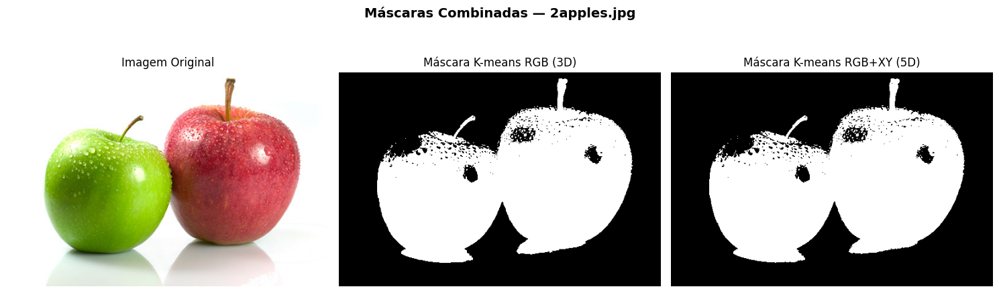

2apples.jpg | RGB: 76248 pixels (39.59%)
2apples.jpg | RGB+XY: 76186 pixels (39.56%)


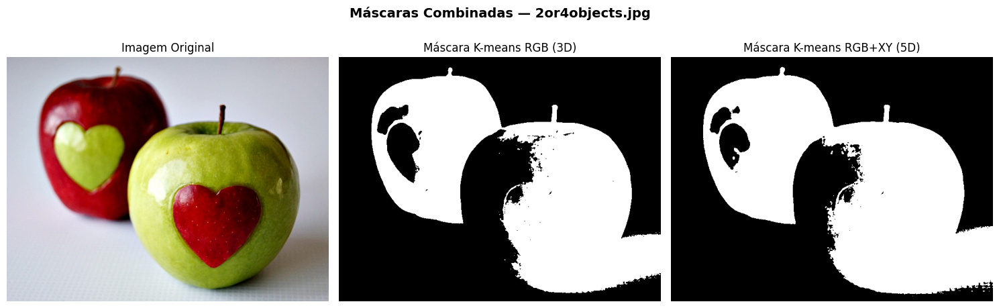

2or4objects.jpg | RGB: 145705 pixels (39.20%)
2or4objects.jpg | RGB+XY: 159858 pixels (43.01%)


In [ ]:

# FUNÇÃO PARA COMBINAR OS CLUSTERS SELECIONADOS
# Constrói uma máscara binária a partir dos agrupamentos
# identificados como pertencentes às regiões das maçãs.

def combinar_clusters(resultado, clusters_selecionados):

    # Recupera os rótulos atribuídos pelo K-means.
    rotulos = resultado["rotulos"]

    # Seleciona os pixels pertencentes a qualquer
    # um dos clusters indicados.
    pixels_selecionados = np.isin(
        rotulos,
        clusters_selecionados
    )

    # Converte a seleção em máscara binária.
    mascara = pixels_selecionados.astype(np.uint8) * 255

    return mascara


# CONFIGURAÇÃO DOS CLUSTERS
# Os índices começam em zero no código:
# Cluster 1 = índice 0, Cluster 2 = índice 1 etc.

clusters_macas = {
    "2apples.jpg": [0, 2],
    "2or4objects.jpg": [0, 2, 3]
}


# CONSTRUÇÃO DAS MÁSCARAS RGB E RGB+XY
# Preserva separadamente os resultados de cada configuração.

mascaras_macas_rgb = {}
mascaras_macas_rgbxy = {}

for nome, clusters in clusters_macas.items():

    # Máscara produzida a partir do K-means RGB.
    mascaras_macas_rgb[nome] = combinar_clusters(
        resultados_kmeans_rgb[nome],
        clusters
    )

    # Máscara produzida a partir do K-means RGB+XY
    # com peso espacial ajustado para 0,25.
    mascaras_macas_rgbxy[nome] = combinar_clusters(
        resultados_rgbxy_peso_025[nome],
        clusters
    )

    # Exibe a imagem original e as duas máscaras.
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(resultados_kmeans_rgb[nome]["original"])
    axes[0].set_title("Imagem Original")

    axes[1].imshow(
        mascaras_macas_rgb[nome],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Máscara K-means RGB (3D)")

    axes[2].imshow(
        mascaras_macas_rgbxy[nome],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[2].set_title("Máscara K-means RGB+XY (5D)")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Máscaras Combinadas — {nome}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # Registra a quantidade de pixels selecionados
    # para cada configuração.
    for metodo, mascara in [
        ("RGB", mascaras_macas_rgb[nome]),
        ("RGB+XY", mascaras_macas_rgbxy[nome])
    ]:

        quantidade = np.count_nonzero(mascara)
        percentual = quantidade / mascara.size * 100

        print(
            f"{nome} | {metodo}: "
            f"{quantidade} pixels ({percentual:.2f}%)"
        )



## 3. Aplicação da abertura morfológica

### Justificativa da implementação

Após a conversão dos agrupamentos K-means em máscaras binárias, observamos pequenas irregularidades nos contornos e regiões classificadas incorretamente.

A abertura morfológica consiste na aplicação sequencial de duas operações: erosão e dilatação, utilizando o mesmo elemento estruturante.

A erosão reduz as regiões brancas e remove pequenas estruturas. Em seguida, a dilatação expande as regiões restantes, recuperando parte de suas dimensões originais sem necessariamente restaurar os elementos removidos.

Inicialmente, utilizaremos um elemento estruturante quadrado de 3 × 3 pixels.

Nossa hipótese é que a abertura poderá eliminar pequenos agrupamentos brancos isolados e reduzir irregularidades presentes nas máscaras. Entretanto, também poderá remover detalhes finos dos objetos, como partes dos talos e contornos.

A operação será implementada manualmente e aplicada às máscaras RGB (3D) e RGB+XY (5D), permitindo comparar seus efeitos nas duas configurações do K-means.


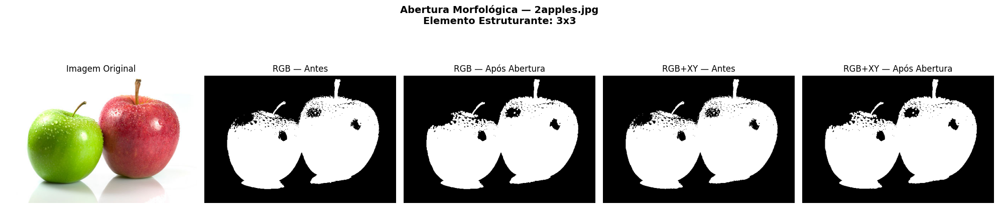

2apples.jpg | RGB: 972 pixels removidos (1.27% da máscara original)
2apples.jpg | RGB+XY: 991 pixels removidos (1.30% da máscara original)


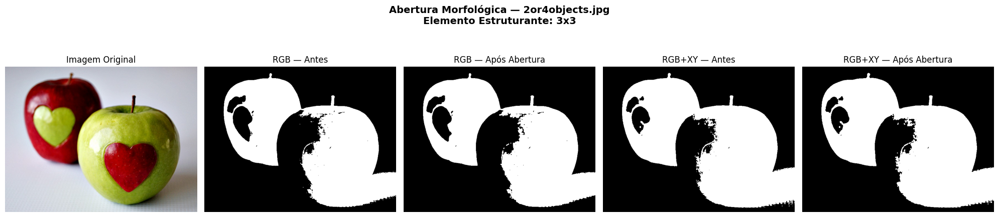

2or4objects.jpg | RGB: 618 pixels removidos (0.42% da máscara original)
2or4objects.jpg | RGB+XY: 635 pixels removidos (0.40% da máscara original)


In [ ]:

# FUNÇÃO DE EROSÃO BINÁRIA
# Aplica manualmente a erosão utilizando um elemento
# estruturante quadrado de tamanho ímpar.

def erosao_binaria_manual(mascara, tamanho=3):

    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser ímpar e positivo.")

    altura, largura = mascara.shape
    margem = tamanho // 2

    # Converte a máscara em valores lógicos.
    pixels = mascara > 0

    # Considera os pixels externos à imagem como fundo.
    expandida = np.pad(
        pixels,
        margem,
        mode="constant",
        constant_values=False
    )

    # Um pixel permanece branco somente quando todos
    # os pontos do elemento estruturante são brancos.
    resultado = np.ones((altura, largura), dtype=bool)

    for dy in range(tamanho):
        for dx in range(tamanho):

            vizinhanca = expandida[
                dy:dy + altura,
                dx:dx + largura
            ]

            resultado &= vizinhanca

    return resultado.astype(np.uint8) * 255


# FUNÇÃO DE DILATAÇÃO BINÁRIA
# Expande as regiões brancas utilizando um elemento
# estruturante quadrado de tamanho ímpar.

def dilatacao_binaria_manual(mascara, tamanho=3):

    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser ímpar e positivo.")

    altura, largura = mascara.shape
    margem = tamanho // 2

    pixels = mascara > 0

    expandida = np.pad(
        pixels,
        margem,
        mode="constant",
        constant_values=False
    )

    # Um pixel será branco quando pelo menos um ponto
    # da vizinhança considerada for branco.
    resultado = np.zeros((altura, largura), dtype=bool)

    for dy in range(tamanho):
        for dx in range(tamanho):

            vizinhanca = expandida[
                dy:dy + altura,
                dx:dx + largura
            ]

            resultado |= vizinhanca

    return resultado.astype(np.uint8) * 255


# FUNÇÃO DE ABERTURA MORFOLÓGICA
# Realiza uma erosão seguida de uma dilatação,
# utilizando o mesmo elemento estruturante.

def abertura_morfologica_manual(mascara, tamanho=3):

    mascara_erodida = erosao_binaria_manual(
        mascara,
        tamanho
    )

    mascara_aberta = dilatacao_binaria_manual(
        mascara_erodida,
        tamanho
    )

    return mascara_aberta


# APLICAÇÃO DA ABERTURA NAS MÁSCARAS DO K-MEANS
# Mantém as máscaras originais preservadas para
# comparar os resultados antes e depois da operação.

TAMANHO_ELEMENTO = 3

mascaras_abertura_rgb = {}
mascaras_abertura_rgbxy = {}

for nome in mascaras_macas_rgb.keys():

    # Executa a abertura nas duas configurações.
    abertura_rgb = abertura_morfologica_manual(
        mascaras_macas_rgb[nome],
        tamanho=TAMANHO_ELEMENTO
    )

    abertura_rgbxy = abertura_morfologica_manual(
        mascaras_macas_rgbxy[nome],
        tamanho=TAMANHO_ELEMENTO
    )

    mascaras_abertura_rgb[nome] = abertura_rgb
    mascaras_abertura_rgbxy[nome] = abertura_rgbxy

    # Organiza a imagem original e as quatro máscaras
    # para comparar os efeitos da abertura.
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    imagens_exibicao = [
        resultados_kmeans_rgb[nome]["original"],
        mascaras_macas_rgb[nome],
        abertura_rgb,
        mascaras_macas_rgbxy[nome],
        abertura_rgbxy
    ]

    titulos = [
        "Imagem Original",
        "RGB — Antes",
        "RGB — Após Abertura",
        "RGB+XY — Antes",
        "RGB+XY — Após Abertura"
    ]

    for indice, imagem in enumerate(imagens_exibicao):

        if indice == 0:
            axes[indice].imshow(imagem)
        else:
            axes[indice].imshow(
                imagem,
                cmap="gray",
                vmin=0,
                vmax=255
            )

        axes[indice].set_title(titulos[indice])
        axes[indice].axis("off")

    fig.suptitle(
        f"Abertura Morfológica — {nome}\n"
        f"Elemento Estruturante: {TAMANHO_ELEMENTO}x{TAMANHO_ELEMENTO}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # Registra a quantidade de pixels brancos removidos.
    for metodo, original, aberta in [
        ("RGB", mascaras_macas_rgb[nome], abertura_rgb),
        ("RGB+XY", mascaras_macas_rgbxy[nome], abertura_rgbxy)
    ]:

        pixels_antes = np.count_nonzero(original)
        pixels_depois = np.count_nonzero(aberta)

        removidos = pixels_antes - pixels_depois

        percentual = (
            removidos / pixels_antes * 100
            if pixels_antes > 0 else 0
        )

        print(
            f"{nome} | {metodo}: "
            f"{removidos} pixels removidos "
            f"({percentual:.2f}% da máscara original)"
        )



### 3.1 Análise dos resultados — Abertura morfológica

A abertura morfológica foi aplicada às máscaras RGB (3D) e RGB+XY (5D) utilizando um elemento estruturante quadrado de 3 × 3 pixels.

Na imagem `2apples.jpg`, a operação removeu 972 pixels da máscara RGB (1,27%) e 991 pixels da máscara RGB+XY (1,30%). Observamos uma redução de pequenas irregularidades, principalmente nas regiões superiores das maçãs, sem alterações significativas em seus formatos.

Na imagem `2or4objects.jpg`, foram removidos 618 pixels na configuração RGB (0,42%) e 635 pixels na RGB+XY (0,40%). O efeito foi menos expressivo, pois boa parte das classificações incorretas corresponde a regiões extensas ou conectadas aos objetos.

Em ambas as imagens, as falhas pretas internas permaneceram, demonstrando que a abertura não é adequada para preencher lacunas nas regiões segmentadas.

Concluímos que a abertura com elemento estruturante 3 × 3 foi útil para remover pequenas estruturas brancas e suavizar irregularidades, preservando a maior parte dos contornos.

Entretanto, a operação não corrigiu os problemas mais extensos da segmentação original, nem eliminou as diferenças entre os resultados RGB e RGB+XY.



## 4. Aplicação do fechamento morfológico

### Justificativa da implementação

Após a abertura morfológica, observamos que pequenas irregularidades brancas foram removidas, mas permaneceram falhas pretas no interior das regiões correspondentes às maçãs.

Para investigar a correção dessas descontinuidades, aplicaremos o fechamento morfológico, composto por uma dilatação seguida de uma erosão.

A dilatação expande inicialmente as regiões brancas, podendo preencher pequenos espaços e aproximar estruturas. A erosão subsequente reduz novamente essas regiões, preservando parte das conexões e preenchimentos realizados.

Utilizaremos inicialmente o mesmo elemento estruturante quadrado de 3 × 3 pixels, permitindo avaliar os efeitos da operação sem alterar excessivamente os contornos.

O fechamento será aplicado às máscaras resultantes da abertura, formando uma sequência de refinamento morfológico.

Nossa hipótese é que a operação poderá preencher pequenas falhas internas, mas não será suficiente para recuperar grandes regiões que foram classificadas incorretamente pelo K-means.

Os resultados serão comparados nas configurações RGB (3D) e RGB+XY (5D).


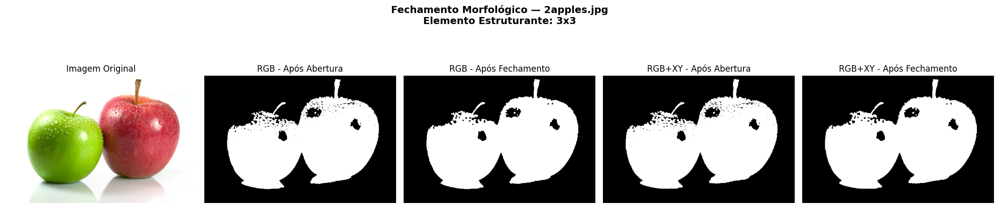

2apples.jpg | RGB: 749 pixels adicionados (1.00% em relação à máscara aberta)
2apples.jpg | RGB+XY: 752 pixels adicionados (1.00% em relação à máscara aberta)


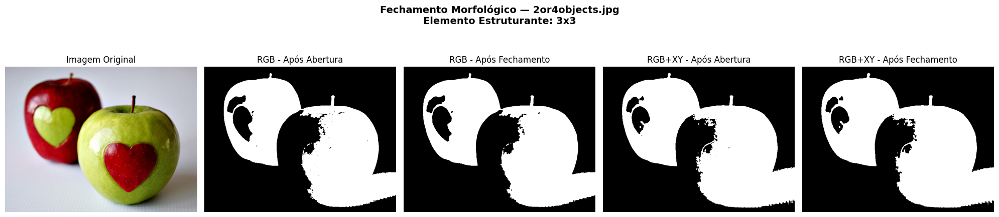

2or4objects.jpg | RGB: 375 pixels adicionados (0.26% em relação à máscara aberta)
2or4objects.jpg | RGB+XY: 328 pixels adicionados (0.21% em relação à máscara aberta)


In [ ]:

# FUNÇÃO DE FECHAMENTO MORFOLÓGICO
# Aplica uma dilatação seguida de uma erosão,
# utilizando o mesmo elemento estruturante.

def fechamento_morfologico_manual(mascara, tamanho=3):

    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser ímpar e positivo.")

    margem = tamanho // 2

    # Expande temporariamente a imagem para preservar
    # o comportamento da operação próximo às bordas.
    mascara_expandida = np.pad(
        mascara,
        margem,
        mode="constant",
        constant_values=0
    )

    # ETAPA 1: DILATAÇÃO
    # Expande as regiões brancas e reduz pequenos
    # espaços pretos existentes entre os pixels.
    mascara_dilatada = dilatacao_binaria_manual(
        mascara_expandida,
        tamanho
    )

    # ETAPA 2: EROSÃO
    # Reduz as regiões expandidas, preservando
    # parte das conexões e preenchimentos realizados.
    mascara_fechada = erosao_binaria_manual(
        mascara_dilatada,
        tamanho
    )

    # Retorna às dimensões originais da imagem.
    if margem > 0:
        mascara_fechada = mascara_fechada[
            margem:-margem,
            margem:-margem
        ]

    return mascara_fechada


# APLICAÇÃO DO FECHAMENTO NAS MÁSCARAS APÓS ABERTURA
# Preserva os resultados intermediários para comparação.

TAMANHO_FECHAMENTO = 3

mascaras_fechamento_rgb = {}
mascaras_fechamento_rgbxy = {}

for nome in mascaras_abertura_rgb.keys():

    # Aplica o fechamento às máscaras RGB.
    fechamento_rgb = fechamento_morfologico_manual(
        mascaras_abertura_rgb[nome],
        tamanho=TAMANHO_FECHAMENTO
    )

    # Aplica o fechamento às máscaras RGB+XY.
    fechamento_rgbxy = fechamento_morfologico_manual(
        mascaras_abertura_rgbxy[nome],
        tamanho=TAMANHO_FECHAMENTO
    )

    # Armazena os resultados finais desta operação.
    mascaras_fechamento_rgb[nome] = fechamento_rgb
    mascaras_fechamento_rgbxy[nome] = fechamento_rgbxy

    # Compara visualmente os resultados antes e
    # depois do fechamento em ambas as configurações.
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    imagens_exibicao = [
        resultados_kmeans_rgb[nome]["original"],
        mascaras_abertura_rgb[nome],
        fechamento_rgb,
        mascaras_abertura_rgbxy[nome],
        fechamento_rgbxy
    ]

    titulos = [
        "Imagem Original",
        "RGB - Após Abertura",
        "RGB - Após Fechamento",
        "RGB+XY - Após Abertura",
        "RGB+XY - Após Fechamento"
    ]

    for indice, imagem in enumerate(imagens_exibicao):

        if indice == 0:
            axes[indice].imshow(imagem)
        else:
            axes[indice].imshow(
                imagem,
                cmap="gray",
                vmin=0,
                vmax=255
            )

        axes[indice].set_title(titulos[indice])
        axes[indice].axis("off")

    fig.suptitle(
        f"Fechamento Morfológico — {nome}\n"
        f"Elemento Estruturante: "
        f"{TAMANHO_FECHAMENTO}x{TAMANHO_FECHAMENTO}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # Registra a quantidade de pixels adicionados
    # após a execução do fechamento morfológico.
    for metodo, antes, depois in [
        (
            "RGB",
            mascaras_abertura_rgb[nome],
            fechamento_rgb
        ),
        (
            "RGB+XY",
            mascaras_abertura_rgbxy[nome],
            fechamento_rgbxy
        )
    ]:

        pixels_antes = np.count_nonzero(antes)
        pixels_depois = np.count_nonzero(depois)

        adicionados = pixels_depois - pixels_antes

        percentual = (
            adicionados / pixels_antes * 100
            if pixels_antes > 0 else 0
        )

        print(
            f"{nome} | {metodo}: "
            f"{adicionados} pixels adicionados "
            f"({percentual:.2f}% em relação à máscara aberta)"
        )



### 4.1 Análise dos resultados — Fechamento morfológico

O fechamento morfológico foi aplicado às máscaras resultantes da abertura, utilizando um elemento estruturante quadrado de 3 × 3 pixels.

Na imagem `2apples.jpg`, a operação acrescentou 749 pixels na configuração RGB (1,00%) e 752 pixels na RGB+XY (1,00%). Observamos o preenchimento de pequenas falhas e uma melhoria discreta na continuidade das regiões brancas, principalmente nas partes superiores das maçãs.

Na imagem `2or4objects.jpg`, foram acrescentados 375 pixels na configuração RGB (0,26%) e 328 pixels na RGB+XY (0,21%). As alterações foram menores, pois muitas das regiões pretas possuem dimensões superiores à capacidade de preenchimento do elemento estruturante utilizado.

Os resultados demonstraram que o fechamento é útil para corrigir pequenas descontinuidades, mas não recupera necessariamente grandes regiões classificadas incorretamente pelo K-means.

Decidimos manter o elemento estruturante 3 × 3, pois ele permitiu observar os efeitos da operação sem provocar alterações excessivas nos contornos dos objetos.

A sequência de abertura e fechamento produziu um refinamento discreto das máscaras, preservando as principais diferenças entre as configurações RGB e RGB+XY.



## 5. Aplicação individual da erosão e dilatação

### Justificativa da implementação

Após analisar os efeitos da abertura e do fechamento, aplicaremos as operações de erosão e dilatação individualmente para observar como modificam os contornos e as dimensões das regiões segmentadas.

A **erosão** reduz as regiões brancas, provocando a retração de seus contornos. Como consequência, estruturas finas podem desaparecer e pequenas regiões podem ser eliminadas.

A **dilatação** expande as regiões brancas, aumentando suas dimensões. Essa operação pode reduzir pequenos espaços entre estruturas, mas também provocar a união de regiões próximas.

As operações serão aplicadas separadamente às máscaras originais do K-means RGB e RGB+XY, utilizando um elemento estruturante quadrado de 3 × 3 pixels.

Nossa hipótese é que a erosão reduzirá a área ocupada pelas maçãs, enquanto a dilatação aumentará essa área. Também esperamos observar alterações nos talos, nas bordas e nos espaços entre os objetos.

A comparação permitirá compreender os efeitos individuais dessas operações, que anteriormente foram utilizadas em sequência na abertura e no fechamento.



2apples.jpg — RGB (3D)
Pixels originais: 76248
Erosão: 5664 pixels removidos (7.43%)
Dilatação: 4438 pixels adicionados (5.82%)

2apples.jpg — RGB+XY (5D)
Pixels originais: 76186
Erosão: 5680 pixels removidos (7.46%)
Dilatação: 4478 pixels adicionados (5.88%)


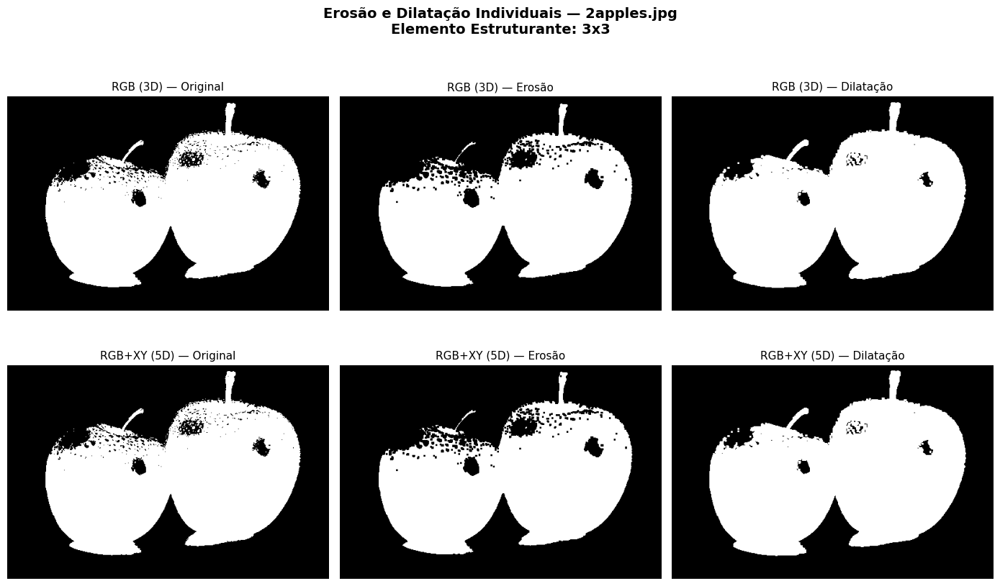


2or4objects.jpg — RGB (3D)
Pixels originais: 145705
Erosão: 5656 pixels removidos (3.88%)
Dilatação: 5272 pixels adicionados (3.62%)

2or4objects.jpg — RGB+XY (5D)
Pixels originais: 159858
Erosão: 5492 pixels removidos (3.44%)
Dilatação: 5283 pixels adicionados (3.30%)


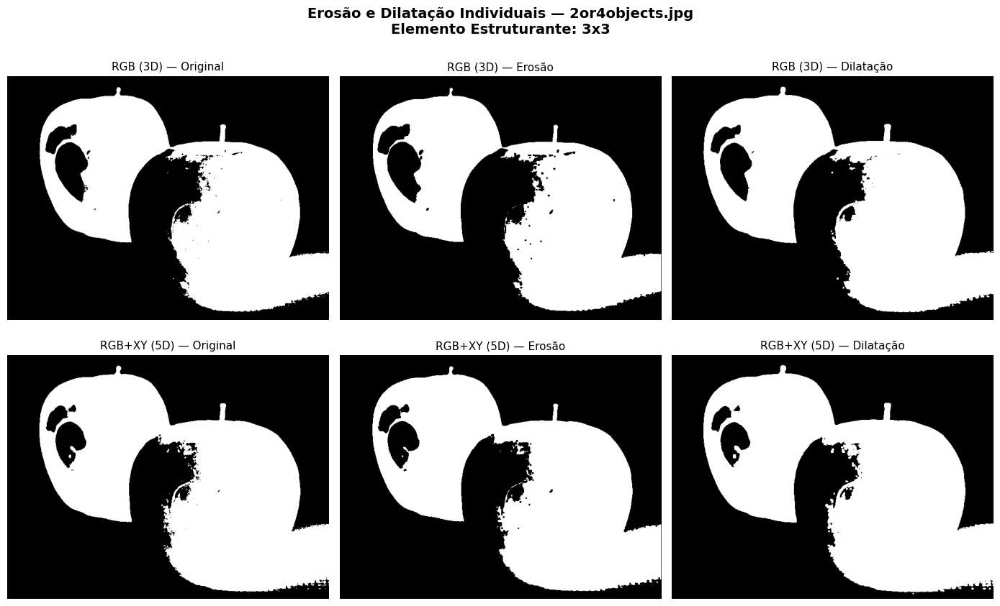

In [ ]:

# EXPERIMENTO COM EROSÃO E DILATAÇÃO INDIVIDUAIS
# Aplica cada operação diretamente às máscaras originais,
# permitindo observar seus efeitos de forma independente.

TAMANHO_OPERACOES = 3

resultados_operacoes_individuais = {}

for nome in mascaras_macas_rgb.keys():

    resultados_operacoes_individuais[nome] = {}

    # Organiza duas linhas de comparação:
    # uma para RGB (3D) e outra para RGB+XY (5D).
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))

    configuracoes = [
        ("RGB (3D)", mascaras_macas_rgb[nome]),
        ("RGB+XY (5D)", mascaras_macas_rgbxy[nome])
    ]

    for linha, (metodo, mascara) in enumerate(configuracoes):

        # Aplica a erosão diretamente à máscara original.
        mascara_erodida = erosao_binaria_manual(
            mascara,
            tamanho=TAMANHO_OPERACOES
        )

        # Aplica a dilatação diretamente à mesma máscara.
        mascara_dilatada = dilatacao_binaria_manual(
            mascara,
            tamanho=TAMANHO_OPERACOES
        )

        # Armazena os resultados de cada operação.
        resultados_operacoes_individuais[nome][metodo] = {
            "original": mascara,
            "erosao": mascara_erodida,
            "dilatacao": mascara_dilatada
        }

        imagens_exibicao = [
            mascara,
            mascara_erodida,
            mascara_dilatada
        ]

        titulos = [
            f"{metodo} — Original",
            f"{metodo} — Erosão",
            f"{metodo} — Dilatação"
        ]

        # Apresenta as três máscaras lado a lado.
        for coluna, imagem in enumerate(imagens_exibicao):

            axes[linha, coluna].imshow(
                imagem,
                cmap="gray",
                vmin=0,
                vmax=255
            )

            axes[linha, coluna].set_title(
                titulos[coluna],
                fontsize=11
            )

            axes[linha, coluna].axis("off")

        # Calcula a quantidade de pixels antes e depois
        # das operações para registrar as mudanças de área.
        pixels_originais = np.count_nonzero(mascara)
        pixels_erosao = np.count_nonzero(mascara_erodida)
        pixels_dilatacao = np.count_nonzero(mascara_dilatada)

        pixels_removidos = pixels_originais - pixels_erosao
        pixels_adicionados = pixels_dilatacao - pixels_originais

        percentual_erosao = (
            pixels_removidos / pixels_originais * 100
            if pixels_originais > 0 else 0
        )

        percentual_dilatacao = (
            pixels_adicionados / pixels_originais * 100
            if pixels_originais > 0 else 0
        )

        print(f"\n{nome} — {metodo}")
        print(f"Pixels originais: {pixels_originais}")

        print(
            f"Erosão: {pixels_removidos} pixels removidos "
            f"({percentual_erosao:.2f}%)"
        )

        print(
            f"Dilatação: {pixels_adicionados} pixels adicionados "
            f"({percentual_dilatacao:.2f}%)"
        )

    fig.suptitle(
        f"Erosão e Dilatação Individuais — {nome}\n"
        f"Elemento Estruturante: {TAMANHO_OPERACOES}x{TAMANHO_OPERACOES}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()



### 5.1 Análise dos resultados — Erosão e dilatação

As operações de erosão e dilatação foram aplicadas individualmente às máscaras originais do K-means, utilizando um elemento estruturante quadrado de 3 × 3 pixels.

**2apples.jpg**

Na configuração RGB, a erosão removeu 5.664 pixels (7,43%), enquanto a dilatação acrescentou 4.438 pixels (5,82%). Na configuração RGB+XY, foram removidos 5.680 pixels (7,46%) e acrescentados 4.478 pixels (5,88%).

Visualmente, a erosão reduziu os contornos das maçãs e afinou algumas estruturas, como os talos. A dilatação expandiu as regiões brancas e diminuiu pequenas falhas internas.

Os resultados foram bastante semelhantes entre RGB e RGB+XY, acompanhando a proximidade das máscaras produzidas pelas duas configurações do K-means.

**2or4objects.jpg**

Na configuração RGB, a erosão removeu 5.656 pixels (3,88%) e a dilatação acrescentou 5.272 pixels (3,62%). Na RGB+XY, foram removidos 5.492 pixels (3,44%) e acrescentados 5.283 pixels (3,30%).

A erosão reduziu as dimensões das regiões brancas, mas também ampliou algumas falhas internas. A dilatação apresentou o comportamento oposto, expandindo as regiões segmentadas e reduzindo pequenas descontinuidades.

Entretanto, as operações não corrigiram os grandes erros de classificação presentes nas máscaras. A dilatação também expandiu regiões do fundo que haviam sido incorretamente incorporadas pelo K-means.

**Considerações**

Os experimentos confirmaram os efeitos fundamentais das operações morfológicas: a erosão reduz as regiões brancas, enquanto a dilatação as expande.

Esses efeitos podem ser úteis ou prejudiciais, dependendo das características da segmentação original.

Concluímos que ambas as operações modificaram as dimensões e os contornos das regiões, mas não foram suficientes para resolver as limitações mais extensas do agrupamento K-means.



## 6. Comparação final — K-means antes e depois da morfologia

Após aplicar abertura, fechamento, erosão e dilatação, realizaremos uma comparação final entre as configurações RGB (3D) e RGB+XY (5D).

Para essa comparação, utilizaremos as máscaras originais e as máscaras refinadas pela sequência de abertura e fechamento, ambas com elemento estruturante 3 × 3.

Nossa hipótese é que a morfologia poderá reduzir pequenas diferenças locais entre as segmentações, principalmente aquelas causadas por ruídos e descontinuidades.

Entretanto, as diferenças maiores produzidas pelos agrupamentos K-means poderão permanecer, pois as operações morfológicas não identificam os objetos semanticamente.

Além da comparação visual, calcularemos a quantidade de pixels com classificações divergentes entre RGB e RGB+XY e a sobreposição entre as máscaras por meio da IoU.

Nesse experimento, a IoU será utilizada exclusivamente para comparar a concordância entre os dois métodos, não representando uma medida de acurácia da segmentação em relação às maçãs reais.


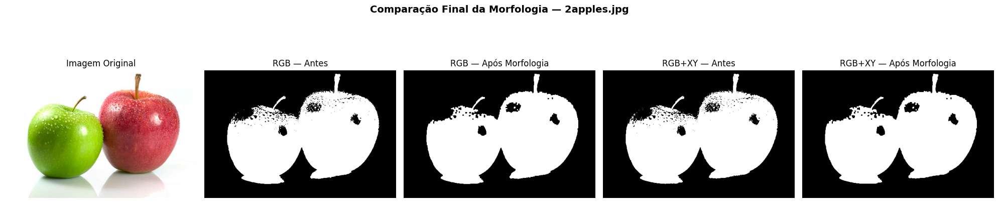

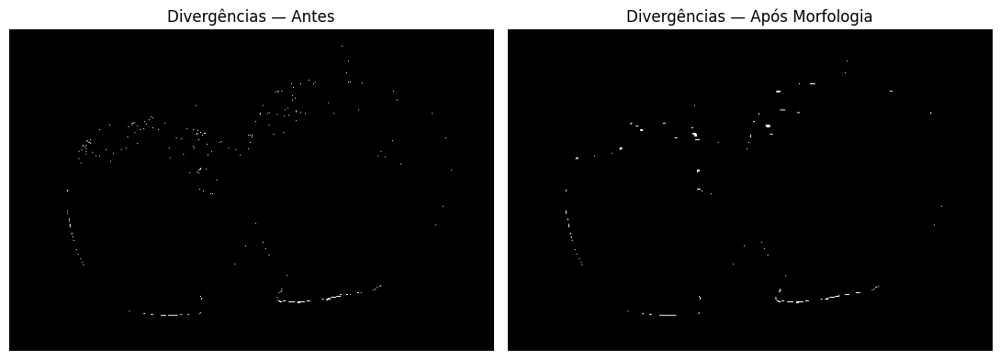


Resultados — 2apples.jpg
Antes: 274 pixels divergentes (0.14%)
Depois: 262 pixels divergentes (0.14%)
Variação das divergências: -12 pixels
IoU entre métodos antes: 0.9964
IoU entre métodos depois: 0.9966


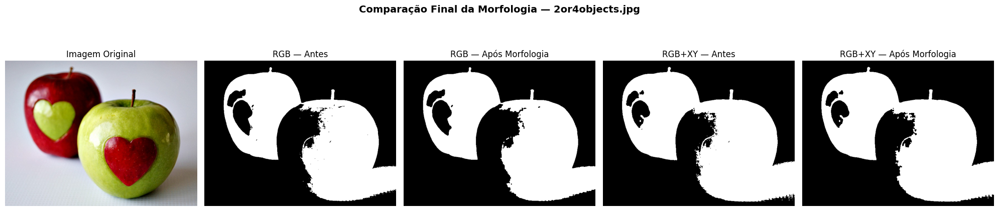

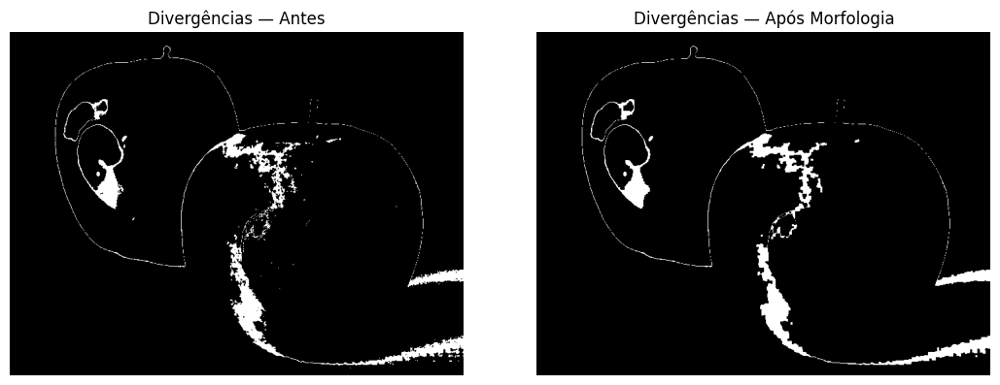


Resultados — 2or4objects.jpg
Antes: 14153 pixels divergentes (3.81%)
Depois: 14089 pixels divergentes (3.79%)
Variação das divergências: -64 pixels
IoU entre métodos antes: 0.9115
IoU entre métodos depois: 0.9117


In [ ]:

# FUNÇÃO PARA CALCULAR A CONCORDÂNCIA ENTRE DUAS MÁSCARAS
# Registra a quantidade de pixels divergentes e a IoU,
# considerando apenas as classificações binárias.

def comparar_mascaras_binarias(mascara_a, mascara_b):

    a = mascara_a > 0
    b = mascara_b > 0

    # Identifica os pixels classificados diferentemente.
    divergencias = np.logical_xor(a, b)

    quantidade_divergencias = np.count_nonzero(divergencias)
    percentual_divergencias = (
        quantidade_divergencias / a.size * 100
    )

    # Calcula a interseção e a união das regiões brancas.
    intersecao = np.count_nonzero(a & b)
    uniao = np.count_nonzero(a | b)

    iou = intersecao / uniao if uniao > 0 else 1.0

    return {
        "divergencias": divergencias,
        "quantidade": quantidade_divergencias,
        "percentual": percentual_divergencias,
        "iou": iou
    }


# COMPARAÇÃO FINAL
# Utiliza as máscaras originais e os resultados após
# a sequência de abertura e fechamento morfológico.

comparacoes_finais = {}

for nome in mascaras_macas_rgb.keys():

    rgb_antes = mascaras_macas_rgb[nome]
    rgbxy_antes = mascaras_macas_rgbxy[nome]

    rgb_depois = mascaras_fechamento_rgb[nome]
    rgbxy_depois = mascaras_fechamento_rgbxy[nome]

    # Calcula a concordância entre RGB e RGB+XY
    # antes e depois do processamento morfológico.
    antes = comparar_mascaras_binarias(
        rgb_antes, rgbxy_antes
    )

    depois = comparar_mascaras_binarias(
        rgb_depois, rgbxy_depois
    )

    comparacoes_finais[nome] = {
        "antes": antes,
        "depois": depois
    }

    # COMPARAÇÃO VISUAL DAS MÁSCARAS
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    imagens = [
        resultados_kmeans_rgb[nome]["original"],
        rgb_antes,
        rgb_depois,
        rgbxy_antes,
        rgbxy_depois
    ]

    titulos = [
        "Imagem Original",
        "RGB — Antes",
        "RGB — Após Morfologia",
        "RGB+XY — Antes",
        "RGB+XY — Após Morfologia"
    ]

    for indice, imagem in enumerate(imagens):

        if indice == 0:
            axes[indice].imshow(imagem)
        else:
            axes[indice].imshow(
                imagem,
                cmap="gray",
                vmin=0,
                vmax=255
            )

        axes[indice].set_title(titulos[indice])
        axes[indice].axis("off")

    fig.suptitle(
        f"Comparação Final da Morfologia — {nome}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # VISUALIZAÇÃO DAS DIFERENÇAS ENTRE OS MÉTODOS
    # Pixels brancos indicam classificações diferentes
    # entre RGB e RGB+XY na mesma posição.

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].imshow(
        antes["divergencias"], cmap="gray"
    )
    axes[0].set_title("Divergências — Antes")

    axes[1].imshow(
        depois["divergencias"], cmap="gray"
    )
    axes[1].set_title("Divergências — Após Morfologia")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # RESULTADOS QUANTITATIVOS
    diferenca = depois["quantidade"] - antes["quantidade"]

    print(f"\nResultados — {nome}")

    print(
        f"Antes: {antes['quantidade']} pixels divergentes "
        f"({antes['percentual']:.2f}%)"
    )

    print(
        f"Depois: {depois['quantidade']} pixels divergentes "
        f"({depois['percentual']:.2f}%)"
    )

    print(f"Variação das divergências: {diferenca:+d} pixels")

    print(f"IoU entre métodos antes: {antes['iou']:.4f}")
    print(f"IoU entre métodos depois: {depois['iou']:.4f}")



## 6.1 Análise comparativa e conclusão da morfologia

Após aplicar as operações morfológicas, comparamos as máscaras produzidas pelo K-means RGB (3D) e RGB+XY (5D), antes e depois da sequência de abertura e fechamento com elemento estruturante 3 × 3.

### A morfologia reduziu as diferenças entre RGB e RGB+XY?

Os resultados demonstraram uma redução discreta nas diferenças entre os métodos.

Na imagem `2apples.jpg`, a quantidade de pixels divergentes diminuiu de 274 para 262, enquanto a IoU entre as máscaras aumentou de 0,9964 para 0,9966.

Na imagem `2or4objects.jpg`, os pixels divergentes diminuíram de 14.153 para 14.089, e a IoU aumentou de 0,9115 para 0,9117.

Portanto, a morfologia reduziu as diferenças entre as configurações, mas o efeito foi pouco expressivo.

Isso ocorreu porque as operações atuaram principalmente sobre pequenas irregularidades, enquanto as diferenças mais significativas estavam relacionadas à distribuição dos agrupamentos produzidos pelo K-means.

É importante destacar que a IoU utilizada nesta comparação representa apenas a concordância entre as máscaras RGB e RGB+XY, não a qualidade da segmentação em relação aos objetos reais.

### Em quais situações a morfologia melhora ou prejudica a separação das maçãs?

A **abertura morfológica** contribuiu para remover pequenos agrupamentos brancos isolados e suavizar irregularidades dos contornos. Entretanto, também pode eliminar estruturas finas que pertencem aos objetos, como partes dos talos.

O **fechamento morfológico** permitiu preencher pequenas falhas pretas e melhorar a continuidade das regiões segmentadas. Porém, não conseguiu recuperar grandes áreas classificadas incorretamente pelo K-means.

A **erosão**, quando aplicada individualmente, reduziu as dimensões das regiões brancas e afinou estruturas, mas também aumentou algumas falhas internas.

A **dilatação** expandiu os contornos e reduziu pequenas descontinuidades. Entretanto, também pode ampliar regiões classificadas incorretamente e aproximar objetos que deveriam permanecer separados.

Na imagem `2apples.jpg`, as operações produziram refinamentos discretos, preservando os formatos principais das maçãs.

Na imagem `2or4objects.jpg`, os resultados demonstraram limitações maiores, especialmente nas regiões de sombra, brilho e nos agrupamentos que incluíram partes do fundo. Como esses erros envolvem áreas extensas, as operações morfológicas com elemento estruturante 3 × 3 não foram suficientes para corrigi-los.

### Conclusão

Os experimentos demonstraram que a morfologia matemática é útil para refinar máscaras binárias, removendo pequenos ruídos, preenchendo falhas e modificando os contornos dos objetos.

Entretanto, sua aplicação não garante uma melhoria significativa na separação das maçãs, especialmente quando a segmentação original apresenta erros extensos.

Concluímos que a eficácia das operações morfológicas depende das características das máscaras, do tamanho do elemento estruturante e da natureza dos erros existentes.

Nas imagens analisadas, a abertura e o fechamento produziram melhorias locais, mas não eliminaram as diferenças fundamentais entre o K-means RGB e o RGB+XY.

Assim, a morfologia mostrou-se uma ferramenta complementar ao processo de segmentação, capaz de refinar os resultados, mas não de substituir a identificação adequada das regiões de interesse.
